<a href="https://colab.research.google.com/github/farrelrassya/LLM-Design-Patterns-Building-Robust-and-Efficient-AI-Systems/blob/main/18.Adversarial_Robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 18 — Adversarial Robustness

*Notebook pendamping untuk* LLM Design Patterns

Model sentimen yang bagus membaca *"a warm but realistic meditation on friendship, family and affection"* sebagai pujian. Ubah tiga kata menjadi salah ketik — *wram*, *rralistic*, *abd* — dan model yang sama bisa membacanya sebagai cercaan, padahal kita masih membaca kalimat yang sama. Bab ini membahas celah semacam itu: **contoh adversarial**, yaitu input yang diubah sedikit dengan sengaja supaya model salah.

Bab buku menyentuh tiga pekerjaan yang berbeda, dan notebook ini memisahkannya dengan tegas:

1. **Membuat gangguan** (*perturbation*): serangan karakter, serangan sinonim, dan pemicu universal.
2. **Adversarial training**: melatih model dengan contoh yang diganggu, di sini dengan FGSM di ruang embedding.
3. **Evaluasi ketahanan**: mengukur model pada input bersih dan input yang diserang, secara berpasangan.

Di akhir, kerangka deployment dari buku dilengkapi dengan detektor sederhana. Sepanjang jalan, dua pertanyaan kita bawa ke setiap listing: *apakah serangan ini benar-benar memakai model yang diserang, dan apakah "robust" yang diukur masih bertahan terhadap serangan yang tidak dipakai saat melatih?*

> **Cara menjalankan.** Pilih runtime GPU di Colab (Runtime > Change runtime type > GPU; T4 cukup), lalu Run all. Sel cek GPU di awal langsung berhenti dengan pesan yang jelas bila GPU tidak bisa dipakai.
>
> Output sengaja dikosongkan karena versi GPU ini belum pernah dijalankan di Colab. Angka yang dikutip di narasi berasal dari run CPU notebook versi sebelumnya, dengan data dan ukuran eksperimen yang sama, dan ditandai *(run sebelumnya)*. Beberapa angka kecil yang dicek ulang dengan kode versi ini di CPU ditandai *(uji lokal di CPU)*. Hasil GPU bisa sedikit berbeda, terutama di bagian training. Listing buku yang tidak jalan apa adanya ditampilkan sebagai kotak Markdown; versi yang berjalan ada di sel kode sesudahnya.

## Persiapan

Ada empat sel pendek: memasang paket yang belum ada, memastikan GPU benar-benar bisa dipakai, menyiapkan impor dan ukuran eksperimen, lalu memuat data dan model. GPU dicek **sebelum** data dan model diunduh, supaya runtime yang salah ketahuan dalam hitungan detik, bukan setelah setengah jam berjalan pelan di CPU.

In [1]:
# Colab sudah membawa torch, transformers, datasets, scikit-learn, scipy, dan matplotlib; sel ini hanya memasang yang belum ada.
# torch sengaja tidak di-install ulang: build bawaan Colab sudah cocok dengan driver CUDA-nya.
import importlib.metadata
import re
import subprocess
import sys


def installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def at_least(version, minimum):
    parts = re.match(r"(\d+)\.(\d+)", version or "")
    return parts is not None and (int(parts[1]), int(parts[2])) >= minimum


need = [p for p in ("torch", "transformers", "datasets", "scikit-learn", "scipy", "matplotlib") if installed_version(p) is None]
if not at_least(installed_version("nltk"), (3, 9)):      # NLTK 3.9+ membaca paket data punkt_tab dan tagger *_eng
    need.append("nltk>=3.9")
if need:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need])
print("paket yang dipasang:", need if need else "tidak ada, semua sudah tersedia")
for p in ("torch", "transformers", "datasets", "nltk", "scikit-learn"):
    print(f"  {p} {installed_version(p)}")

paket yang dipasang: tidak ada, semua sudah tersedia
  torch 2.11.0+cu130
  transformers 5.20.2
  datasets 4.8.5
  nltk 3.9.1
  scikit-learn 1.6.1


Cek GPU di bawah tidak berhenti di `torch.cuda.is_available()`. Ia mengalokasikan matriks di GPU, mengalikannya, lalu menunggu hasilnya (`synchronize`), karena driver yang bermasalah sering baru ketahuan saat ada operasi sungguhan. Bila CUDA tidak bisa dipakai, sel ini berhenti; CPU hanya dipakai bila kita sendiri mengubah `ALLOW_CPU` menjadi `True`.

Semua model di bab ini kecil (66–124 juta parameter), jadi semuanya dijalankan dalam **FP32** di GPU apa pun, termasuk T4 yang tidak punya BF16 native. FP32 juga menjaga gradien yang dipakai FGSM dan pencarian pemicu tetap utuh.

In [2]:
import torch

ALLOW_CPU = False   # True = uji alur versi kecil di CPU (lambat; angkanya tidak untuk dibaca)


def cuda_problem():
    """None bila CUDA benar-benar bisa dipakai; selain itu, alasan kegagalannya."""
    if not torch.cuda.is_available():
        return "torch.cuda.is_available() bernilai False"
    try:
        x = torch.randn(1024, 1024, device="cuda")
        y = x @ x
        torch.cuda.synchronize()
        finite = bool(torch.isfinite(y).all())
        del x, y
        torch.cuda.empty_cache()
    except Exception as e:    # driver atau runtime yang rusak sering baru ketahuan di operasi pertama
        return f"operasi uji di GPU gagal ({type(e).__name__}: {e})"
    return None if finite else "hasil operasi uji di GPU tidak finite"


problem = cuda_problem()
if problem is None:
    DEVICE = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    free, total = torch.cuda.mem_get_info()
    print(f"GPU siap: {props.name} | compute capability {props.major}.{props.minor} | "
          f"VRAM bebas {free / 2**30:.1f} dari {total / 2**30:.1f} GiB")
    print(f"BF16 native: {'ya' if props.major >= 8 else 'tidak'} | presisi yang dipakai notebook ini: FP32")
elif ALLOW_CPU:
    DEVICE = torch.device("cpu")
    print(f"CUDA tidak bisa dipakai ({problem}).")
    print("ALLOW_CPU=True: lanjut di CPU dengan ukuran eksperimen kecil. Angkanya tidak sebanding dengan run GPU.")
else:
    raise RuntimeError(
        f"CUDA tidak bisa dipakai ({problem}).\n"
        "Notebook ini dirancang untuk GPU. Di Colab: Runtime > Change runtime type > pilih GPU (misalnya T4) > Save, "
        "lalu jalankan ulang dari sel pertama.\n"
        "Untuk sekadar menguji alur di CPU dengan ukuran kecil, ubah ALLOW_CPU = True di sel ini."
    )

GPU siap: Tesla T4 | compute capability 7.5 | VRAM bebas 14.4 dari 14.6 GiB
BF16 native: tidak | presisi yang dipakai notebook ini: FP32


Sel berikut menyiapkan impor, seed, dan ukuran eksperimen. Di GPU, ukurannya sama dengan run sebelumnya — misalnya 300 kalimat untuk serangan greedy dan 1.200 kalimat untuk training — supaya angka di narasi bisa dibandingkan. Bila `ALLOW_CPU=True`, semuanya diperkecil drastis: cukup untuk memastikan setiap sel jalan, tidak cukup untuk dibaca angkanya.

In [3]:
import gc
import os
import random
import time
import warnings
from collections import Counter

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import datasets
import matplotlib.pyplot as plt
import nltk
import numpy as np
import scipy.stats
import torch.nn.functional as F
import transformers
from datasets import load_dataset

transformers.logging.set_verbosity_error()
datasets.logging.set_verbosity_error()
datasets.disable_progress_bars()
transformers.utils.logging.disable_progress_bar()
warnings.filterwarnings("ignore", category=FutureWarning)

ON_GPU = DEVICE.type == "cuda"
CFG = {   # ukuran eksperimen: di GPU sama dengan run sebelumnya; di CPU hanya cukup untuk menguji alur
    "n_val": None if ON_GPU else 96,          # None = 872 kalimat validation SST-2 penuh
    "attack_seeds": 5 if ON_GPU else 2,
    "n_uth1": 300 if ON_GPU else 12,          # kalimat untuk serangan greedy
    "n_query_ctrl": 100 if ON_GPU else 6,     # kalimat untuk kontrol jumlah pertanyaan dan serangan adaptif
    "n_rand_trig": 50 if ON_GPU else 4,
    "n_trig_eval": 150 if ON_GPU else 10,
    "n_trig_search": 100 if ON_GPU else 8,
    "trig_rounds": 3 if ON_GPU else 1,
    "n_train": 1200 if ON_GPU else 64,
    "sweep": ([(0.0, 0), (0.003, 0), (0.01, 0), (0.03, 0), (0.1, 0), (0.0, 1), (0.003, 1), (0.01, 1), (0.1, 1)]
              if ON_GPU else [(0.0, 0), (0.1, 0)]),
    "n_greedy_sweep": 100 if ON_GPU else 5,
}
print("profil:", "GPU, ukuran penuh" if ON_GPU else "CPU, ukuran kecil (hanya uji alur)")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | datasets {datasets.__version__} | nltk {nltk.__version__}")


def sync():
    """Tunggu pekerjaan GPU selesai sebelum mengukur waktu."""
    if ON_GPU:
        torch.cuda.synchronize()


def free_gpu():
    """Lepaskan memori GPU yang tidak lagi dipakai, di antara eksperimen."""
    gc.collect()
    if ON_GPU:
        torch.cuda.empty_cache()


torch.manual_seed(42)

profil: GPU, ukuran penuh
torch 2.11.0+cu130 | transformers 5.20.2 | datasets 4.8.5 | nltk 3.9.1


Bahan bab ini adalah **SST-2**, kumpulan kalimat ulasan film berlabel positif atau negatif, dan model yang akan kita serang: DistilBERT yang sudah di-fine-tune untuk SST-2. Fungsi `predict_proba` mengembalikan peluang negatif dan positif per kalimat. Ia memindahkan setiap batch ke GPU, lalu mengembalikan hasilnya ke CPU sebagai NumPy, karena metrik dan plot dihitung di CPU.

`device_report` memeriksa bahwa *semua* parameter model ada di GPU. Mencetak "GPU tersedia" saja tidak cukup: model yang lupa dipindah tetap jalan, hanya diam-diam di CPU.

In [4]:
sst_tr = load_dataset("nyu-mll/glue", "sst2", split="train")
sst_val = load_dataset("nyu-mll/glue", "sst2", split="validation")
if CFG["n_val"] is not None:
    sst_val = sst_val.select(range(CFG["n_val"]))
X_val = [s.strip() for s in sst_val["sentence"]]
Y_val = np.array(sst_val["label"])
print(f"SST-2: train {len(sst_tr)} kalimat, validation {len(X_val)} (proporsi positif {Y_val.mean():.3f})")

SST2 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
tok = transformers.AutoTokenizer.from_pretrained(SST2)
clf = transformers.AutoModelForSequenceClassification.from_pretrained(SST2).to(DEVICE).eval()


def device_report(model, name):
    """Hentikan notebook bila ada parameter model yang tidak berada di DEVICE."""
    found = {p.device.type for p in model.parameters()}
    assert found == {DEVICE.type}, f"{name}: parameter ada di {found}, seharusnya {DEVICE.type}"
    n_params = sum(p.numel() for p in model.parameters())
    return f"{name}: {n_params / 1e6:.0f}M parameter, semuanya di {DEVICE.type}"


@torch.no_grad()
def predict_proba(texts, model=None, bs=64):
    """[P(negatif), P(positif)] per kalimat. Batch diurutkan menurut panjang agar padding minimal."""
    model = clf if model is None else model
    texts = list(texts)
    order = np.argsort([len(t) for t in texts], kind="stable")
    out = np.zeros((len(texts), 2), dtype=np.float32)
    for i in range(0, len(texts), bs):
        ix = order[i:i + bs]
        batch = tok([texts[j] for j in ix], return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
        probs = torch.softmax(model(**batch).logits.float(), dim=-1)
        out[ix] = probs.cpu().numpy()
    return out


print(device_report(clf, "DistilBERT SST-2"))
t0 = time.time()
P_val = predict_proba(X_val)
pred_val = P_val.argmax(1)
ok_val = pred_val == Y_val
majority = max(Y_val.mean(), 1 - Y_val.mean())
print(f"akurasi bersih {ok_val.mean():.3f} | baseline mayoritas {majority:.3f} | {time.time() - t0:.1f} s untuk {len(X_val)} kalimat")

SST-2: train 67349 kalimat, validation 872 (proporsi positif 0.509)
DistilBERT SST-2: 67M parameter, semuanya di cuda
akurasi bersih 0.911 | baseline mayoritas 0.509 | 2.0 s untuk 872 kalimat


Pada 872 kalimat validation, akurasi bersihnya 0,911, sedangkan **baseline mayoritas** — selalu menebak kelas yang paling banyak — hanya 0,509 *(run sebelumnya)*. Model ini jauh di atas tebakan buta, dan 0,911 adalah titik awal yang akan kita coba runtuhkan. Baseline mayoritas akan muncul lagi nanti sebagai penanda model yang sudah tidak belajar apa-apa.

**Contoh pembuka.** Sebelum masuk ke listing buku, lihat dulu masalahnya. Kalimat kedua di bawah adalah hasil serangan greedy yang akan kita bangun di bagian *Bertanya ke model*: tiga kata, masing-masing diberi satu salah ketik.

In [5]:
pair = ["a warm but realistic meditation on friendship , family and affection .",
        "a wram but rralistic meditation on friendship , family abd affection ."]
for text, p_pos in zip(pair, predict_proba(pair)[:, 1]):
    print(f"P(positif) {p_pos:.4f} | {text}")

P(positif) 0.9999 | a warm but realistic meditation on friendship , family and affection .
P(positif) 0.0813 | a wram but rralistic meditation on friendship , family abd affection .


Kalimat asli mendapat peluang positif hampir 1, sedangkan versi salah ketiknya jatuh jauh di bawah 0,5 (uji lokal di CPU: 0,9999 lawan 0,0813). Bagi kita, *wram*, *rralistic*, dan *abd* tetap terbaca sebagai *warm*, *realistic*, dan *and*; bagi model, tiga salah ketik itu cukup untuk membalik label. Sisa bab ini menjawab dua pertanyaan: bagaimana perubahan semacam ini ditemukan, dan bisakah model dilatih agar tahan terhadapnya?

## Jenis serangan teks

Buku membagi serangan teks menurut ukuran perubahannya:

- **tingkat karakter**: huruf diubah, misalnya menjadi salah ketik (*wram* untuk *warm* di contoh pembuka);
- **tingkat kata**: kata diganti sinonimnya;
- **tingkat kalimat**: struktur kalimat diubah tanpa mengubah maknanya.

Jenis keempat adalah **pemicu universal** (*universal adversarial trigger*): frasa pendek yang, bila ditempelkan ke input apa saja, membuat model salah pada banyak input sekaligus. Buku memberi contoh seperti *invisible carpet notebook* untuk model sentimen. Tingkat kalimat tidak punya listing di buku, jadi notebook ini mencoba tiga jenis lainnya.

### Serangan karakter

Listing pertama mengganti setiap huruf, dengan peluang `prob=0.1`, dengan huruf acak. Baris pertama sel adalah tambahan notebook (seed, supaya contohnya bisa diulang); sisanya listing buku apa adanya. Seperti semua manipulasi teks di bab ini, fungsi ini murni operasi string dan berjalan di CPU.

In [6]:
random.seed(42)   # tambahan notebook: agar contoh di bawah bisa diulang. Listing buku dimulai di baris berikutnya.
import random
import string
def character_level_attack(text, prob=0.1):
    def modify_char(c):
        if random.random() < prob:
            return random.choice(string.ascii_letters) if c.isalpha() else c
        return c
    return ''.join(modify_char(c) for c in text)
# Example usage
original_text = "The quick brown fox jumps over the lazy dog."
attacked_text = character_level_attack(original_text)
print(f"Original: {original_text}")
print(f"Attacked: {attacked_text}")

Original: The quick brown fox jumps over the lazy dog.
Attacked: Tre quicf bmown fox jumps oveD the lazy doo.


Dengan seed 42, kalimat contoh menjadi *Tre quicf bmown fox jumps oveD the lazy doo.*: lima dari sembilan kata kena satu huruf. Perhatikan pengganti huruf besar seperti *oveD*: kode mengundi dari 52 huruf `string.ascii_letters`, kecil maupun besar. Prosa buku menggambarkan hasilnya seperti salah ketik (*The* menjadi *Tge*), padahal kode tidak memilih tombol yang bertetangga di keyboard.

Dua sel berikut menjawab dua hal: seberapa sering hasilnya memang mirip salah ketik, dan seberapa besar efeknya pada model. Untuk yang kedua, setiap kalimat validation diserang dengan lima seed berbeda.

In [7]:
# (CPU) Jenis perubahan yang dibuat character_level_attack: 20.000 kali serangan pada kalimat contoh
ROWS = ["qwertyuiop", "asdfghjkl", "zxcvbnm"]


def kb_neighbors(c):
    """Tetangga QWERTY: kiri-kanan, dua tombol di baris atas, dua di baris bawah."""
    for r, row in enumerate(ROWS):
        if c in row:
            j = row.index(c)
            near = set(row[max(j - 1, 0):j + 2]) - {c}
            if r > 0:
                near |= set(ROWS[r - 1][j:j + 2])
            if r < 2:
                near |= set(ROWS[r + 1][max(j - 1, 0):j + 1])
            return near
    return set()


KB = {c: kb_neighbors(c) for c in "abcdefghijklmnopqrstuvwxyz"}
random.seed(0)
changes = Counter()
for _ in range(20000):
    attacked = character_level_attack(original_text)
    for o, a in zip(original_text, attacked):
        if o.isalpha() and a != o:
            changes["berubah"] += 1
            changes["huruf besar"] += a.isupper()
            changes["tetangga keyboard"] += a.lower() in KB[o.lower()]
print(f"dari huruf yang berubah: huruf besar {changes['huruf besar'] / changes['berubah']:.3f} | "
      f"tetangga keyboard {changes['tetangga keyboard'] / changes['berubah']:.3f}")

dari huruf yang berubah: huruf besar 0.513 | tetangga keyboard 0.163


In [8]:
def n_wordpieces(texts):
    return np.mean([len(tok.tokenize(t)) for t in texts])


print(f"bersih: akurasi {ok_val.mean():.3f} | wordpiece per kalimat {n_wordpieces(X_val):.1f}")
char_rows = []
for seed in range(CFG["attack_seeds"]):
    random.seed(seed)
    adv = [character_level_attack(s) for s in X_val]      # CPU: manipulasi string
    pred = predict_proba(adv).argmax(1)                   # GPU: prediksi model
    char_rows.append(((pred == Y_val).mean(), (pred != Y_val)[ok_val].mean(), n_wordpieces(adv)))
    print(f"seed {seed}: akurasi teradversarial {char_rows[-1][0]:.3f} | "
          f"yang tadinya benar jadi salah {char_rows[-1][1]:.3f} | wordpiece per kalimat {char_rows[-1][2]:.1f}")
cr = np.array(char_rows)
print(f"rata-rata {len(cr)} seed: akurasi teradversarial {cr[:, 0].mean():.3f} | yang tadinya benar jadi salah {cr[:, 1].mean():.3f}")

bersih: akurasi 0.911 | wordpiece per kalimat 23.2
seed 0: akurasi teradversarial 0.735 | yang tadinya benar jadi salah 0.232 | wordpiece per kalimat 32.7
seed 1: akurasi teradversarial 0.761 | yang tadinya benar jadi salah 0.212 | wordpiece per kalimat 32.5
seed 2: akurasi teradversarial 0.758 | yang tadinya benar jadi salah 0.215 | wordpiece per kalimat 32.6
seed 3: akurasi teradversarial 0.745 | yang tadinya benar jadi salah 0.225 | wordpiece per kalimat 32.6
seed 4: akurasi teradversarial 0.722 | yang tadinya benar jadi salah 0.246 | wordpiece per kalimat 32.7
rata-rata 5 seed: akurasi teradversarial 0.744 | yang tadinya benar jadi salah 0.226


**Hasilnya lebih mirip noise daripada salah ketik.** Sekitar setengah huruf pengganti (0,51) adalah huruf besar, dan hanya 0,16 yang bertetangga di keyboard dengan huruf aslinya *(run sebelumnya)*. Salah ketik seperti *Tge* adalah minoritas.

**Noise ini tetap merusak.** Akurasi turun dari 0,911 ke rata-rata 0,744 atas lima seed *(run sebelumnya)*. Petunjuknya ada di angka *wordpiece per kalimat*. **Wordpiece** adalah potongan kata di kosakata tokenizer DistilBERT: kata yang ada di kosakata tetap satu potongan, yang tidak ada dipecah menjadi beberapa. Kata yang rusak biasanya tidak ada di kosakata, jadi jumlah potongan per kalimat naik dari sekitar 23 ke 33. Model melihat deretan potongan yang asing, bukan kata yang sedikit salah eja.

Output tadi memakai dua ukuran yang akan sering muncul, dan keduanya tidak sama:

- **akurasi teradversarial** dihitung pada *semua* kalimat setelah diserang (0,744);
- **tingkat keberhasilan serangan** hanya melihat kalimat yang tadinya diklasifikasi benar, lalu menghitung berapa bagian yang berubah menjadi salah (0,226, kolom *yang tadinya benar jadi salah*).

Ukuran kedua lebih tepat untuk menilai sebuah serangan, karena kalimat yang sudah salah sejak awal tidak bisa "dibalik".

Ada satu hal yang *tidak* dilakukan fungsi ini: ia tidak pernah bertanya ke model. Huruf diganti secara acak, tanpa melihat apakah perubahan itu menyesatkan model. Jadi yang diukur di sini adalah ketahanan terhadap noise huruf acak. Bagian *Bertanya ke model* nanti mengukur seberapa jauh bedanya dengan serangan yang memakai umpan balik model.

### Serangan sinonim

Serangan tingkat kata mengganti kata dengan sinonimnya dari **WordNet**, kamus leksikal yang mengelompokkan kata ke dalam *sinset* (himpunan kata bermakna sama) per kelas kata: nomina `n`, verba `v`, adjektiva `a`, dan adverbia `r`. Untuk tahu kelas sebuah kata di dalam kalimat, listing buku memakai *POS tagger* NLTK, yang memberi label seperti `NN` (nomina), `VBD` (verba lampau), atau `JJ` (adjektiva).

> **Listing buku: unduhan NLTK yang sudah usang**
>
> ```python
> nltk.download('wordnet')
> nltk.download('averaged_perceptron_tagger')
> ...
> words = nltk.word_tokenize(text)
> pos_tags = nltk.pos_tag(words)
> ```
>
> Sejak NLTK 3.9, `word_tokenize` membaca paket data `punkt_tab` dan `pos_tag` membaca `averaged_perceptron_tagger_eng`. Listing buku tidak mengunduh keduanya. Di run sebelumnya (NLTK 3.10.3), pemanggilan pertama `word_level_attack` berhenti dengan `LookupError: Resource 'punkt_tab' not found`; setelah paket itu diunduh, muncul `LookupError` yang sama untuk `averaged_perceptron_tagger_eng`. Sel berikut mengunduh paket yang benar; fungsi serangannya sendiri tidak diubah.

In [9]:
# (CPU) Paket data yang dibaca NLTK 3.9+. Semua langkah NLTK/WordNet di bab ini adalah pembukuan string di CPU.
from nltk.corpus import wordnet

for package in ("wordnet", "punkt_tab", "averaged_perceptron_tagger_eng"):
    assert nltk.download(package, quiet=True), f"gagal mengunduh data NLTK '{package}'"


def get_synonyms(word, pos):        # listing buku, dengan satu perubahan: sorted(...) menggantikan list(...)
    synonyms = set()
    for syn in wordnet.synsets(word):
        if syn.pos() == pos:
            synonyms.update(
                lemma.name()
                for lemma in syn.lemmas()
                if lemma.name() != word
            )
    return sorted(synonyms)

Satu-satunya perubahan pada `get_synonyms` adalah `sorted(...)` di baris terakhir. Versi buku mengembalikan `list(set(...))`, dan urutan sebuah set berisi string ikut berubah setiap kali Python dijalankan ulang (hash string diacak per proses). Akibatnya `random.choice` memilih sinonim yang berbeda walau seed-nya sama. Di run sebelumnya, empat proses dengan `PYTHONHASHSEED` berbeda (0–3) dan `random.seed(0)` yang sama memilih *transmit*, *deal*, *channel*, dan *acquit* untuk kata yang sama. Dengan `sorted`, hasilnya bisa diulang. Angka serangan sinonim *(run sebelumnya)* di bab ini masih berasal dari versi tanpa `sorted`: kata yang diganti tetap sama, tetapi penggantinya bisa lain, jadi output di sini akan sedikit berbeda.

Fungsi serangannya, persis seperti di buku:

In [10]:
def word_level_attack(text, prob=0.2):
    words = nltk.word_tokenize(text)
    pos_tags = nltk.pos_tag(words)
    attacked_words = []
    for word, pos in pos_tags:
        if random.random() < prob:
            wordnet_pos = {'NN': 'n', 'JJ': 'a', 'VB': 'v',
                           'RB': 'r'}.get(pos[:2])
            if wordnet_pos:
                synonyms = get_synonyms(word, wordnet_pos)
                if synonyms:
                    attacked_words.append(random.choice(synonyms))
                    continue
        attacked_words.append(word)
    return ' '.join(attacked_words)
# Example usage
original_text = "The intelligent scientist conducted groundbreaking research."
attacked_text = word_level_attack(original_text)
print(f"Original: {original_text}")
print(f"Attacked: {attacked_text}")

Original: The intelligent scientist conducted groundbreaking research.
Attacked: The intelligent scientist conducted groundbreaking research .


Contoh pemakaian buku sekarang jalan, tapi tidak pernah menghasilkan penggantian seperti di prosa buku (*intelligent* menjadi *smart* atau *clever*). Sel berikut menjalankan contoh yang sama dengan enam seed, lalu membedah kata mana yang sebenarnya punya kandidat pengganti.

In [11]:
for seed in range(6):
    random.seed(seed)
    print(f"seed {seed}: {word_level_attack(original_text)}")

WN_POS = {'NN': 'n', 'JJ': 'a', 'VB': 'v', 'RB': 'r'}     # peta POS di listing buku
print(f"\n{'kata':<15}{'tag':<6}{'kelas':<7}kandidat")
for w, t in nltk.pos_tag(nltk.word_tokenize(original_text)):
    p = WN_POS.get(t[:2])
    cands = get_synonyms(w, p) if p else []
    print(f"{w:<15}{t:<6}{p or '-':<7}{len(cands):>2} {cands}")
print("\n'intelligent' sebagai adjektiva satelit (kelas 's'):", get_synonyms("intelligent", "s"))

seed 0: The intelligent scientist conducted groundbreaking research .
seed 1: The intelligent scientist conducted groundbreaking research .
seed 2: The intelligent scientist channel groundbreaking research .
seed 3: The intelligent scientist conducted groundbreaking enquiry .
seed 4: The intelligent scientist behave groundbreaking research .
seed 5: The intelligent scientist conducted groundbreaking research .

kata           tag   kelas  kandidat
The            DT    -       0 []
intelligent    JJ    a       0 []
scientist      NN    n       0 []
conducted      VBD   v      17 ['acquit', 'bear', 'behave', 'carry', 'carry_on', 'channel', 'comport', 'conduct', 'convey', 'deal', 'deport', 'direct', 'guide', 'impart', 'lead', 'take', 'transmit']
groundbreaking VBG   v       0 []
research       NN    n       2 ['enquiry', 'inquiry']
.              .     -       0 []

'intelligent' sebagai adjektiva satelit (kelas 's'): ['healthy', 'level-headed', 'levelheaded', 'reasoning', 'sound', 'think

Dari tujuh token, hanya dua yang punya kandidat:

- ***conducted*** punya 17 kandidat, semuanya bentuk dasar, jadi kala lampaunya hilang. Daftarnya bahkan memuat *conduct*, kata yang sama, dan *carry_on*, yang membawa garis bawah dari nama lemma WordNet. Kandidat juga diambil dari semua makna kata sekaligus, jadi di seed 2 dan 4 *conducted* berubah menjadi *channel* dan *behave*, makna yang sama sekali lain.
- ***research*** punya *enquiry* dan *inquiry*.

*Intelligent* tidak punya kandidat karena WordNet menyimpan banyak adjektiva sebagai **adjektiva satelit** (kelas `s`): sinset adjektiva yang dikelompokkan di sekitar adjektiva inti (kelas `a`) yang maknanya mirip. Peta POS buku hanya mengenal `a`, jadi semua adjektiva satelit terlewat. Baris terakhir output memperlihatkan bahwa lewat `s`, *intelligent* langsung punya kandidat. *Groundbreaking* ditag sebagai verba (`VBG`), dan sebagai verba ia tidak punya sinonim. Karena itulah beberapa seed tidak mengubah satu kata pun, dan satu-satunya jejak yang selalu muncul adalah spasi sebelum titik (*research .*): kalimat dipecah menjadi token lalu disambung lagi dengan `' '.join`.

Sel berikut mengukur seberapa umum masalah adjektiva satelit di SST-2, lalu efek serangan ini pada model.

In [12]:
toks_val = [nltk.word_tokenize(s) for s in X_val]
tags_val = nltk.pos_tag_sents(toks_val)
adjectives = [w for sent in tags_val for w, t in sent if t.startswith("JJ")]
via_a = np.mean([bool(get_synonyms(w, "a")) for w in adjectives])
via_as = np.mean([bool(get_synonyms(w, "a") or get_synonyms(w, "s")) for w in adjectives])
print(f"{len(adjectives)} adjektiva (JJ) di validation: punya sinonim lewat 'a' saja {via_a:.3f}, lewat 'a' atau 's' {via_as:.3f}")

word_rows = []
for seed in range(CFG["attack_seeds"]):
    random.seed(seed)
    adv = [word_level_attack(s) for s in X_val]
    pred = predict_proba(adv).argmax(1)
    word_rows.append(((pred == Y_val).mean(), (pred != Y_val)[ok_val].mean()))
    print(f"seed {seed}: akurasi teradversarial {word_rows[-1][0]:.3f} | yang tadinya benar jadi salah {word_rows[-1][1]:.3f}")
wr = np.array(word_rows)
print(f"rata-rata {len(wr)} seed: akurasi teradversarial {wr[:, 0].mean():.3f} | yang tadinya benar jadi salah {wr[:, 1].mean():.3f}")

1943 adjektiva (JJ) di validation: punya sinonim lewat 'a' saja 0.248, lewat 'a' atau 's' 0.695
seed 0: akurasi teradversarial 0.888 | yang tadinya benar jadi salah 0.043
seed 1: akurasi teradversarial 0.900 | yang tadinya benar jadi salah 0.033
seed 2: akurasi teradversarial 0.889 | yang tadinya benar jadi salah 0.038
seed 3: akurasi teradversarial 0.889 | yang tadinya benar jadi salah 0.035
seed 4: akurasi teradversarial 0.890 | yang tadinya benar jadi salah 0.034
rata-rata 5 seed: akurasi teradversarial 0.891 | yang tadinya benar jadi salah 0.037


Hanya sekitar seperempat adjektiva di SST-2 (0,248) yang punya sinonim lewat kelas `a`, lawan 0,695 bila adjektiva satelit ikut dihitung *(run sebelumnya)*. Padahal adjektiva adalah pembawa sentimen yang paling jelas (*warm*, *bleak*, *charming*), dan tiga perempatnya tidak bisa disentuh peta POS buku.

Akibatnya serangan ini lemah: akurasi hanya turun dari 0,911 ke sekitar 0,89, dan hanya sekitar 0,04 kalimat yang tadinya benar menjadi salah, lawan 0,23 untuk serangan karakter *(run sebelumnya)*. Seperti serangan karakter, ia juga tidak pernah bertanya ke model.

## Bertanya ke model: serangan yang benar-benar adversarial

Kedua serangan buku buta terhadap model. Penyerang sungguhan biasanya bisa *bertanya*: mengirim varian kalimat dan membaca peluang yang dikembalikan model. Ini disebut serangan **black-box**, karena penyerang tidak melihat bobot atau gradien, hanya keluaran.

Strategi paling sederhana adalah **greedy**, versi ringkas dari pola TextFooler (Jin dkk., 2020) dan TextBugger (Li dkk., 2019):

1. Cari kata yang paling penting: hapus satu kata, lalu lihat seberapa jauh peluang label benar turun.
2. Mulai dari kata terpenting, coba hingga 12 kandidat pengganti dan pilih yang paling menurunkan peluang label benar.
3. Berhenti begitu label berbalik, atau setelah 3 kata diubah.

Kandidatnya ada dua jenis: salah ketik yang memang mirip ketikan manusia (tukar dua huruf bersebelahan, hapus satu huruf, atau ganti dengan tetangga keyboard; huruf pertama tidak pernah diubah), dan sinonim WordNet satu kata, kali ini dengan adjektiva satelit ikut dihitung.

Sel ini hanya berisi definisi. Setiap "pertanyaan" penyerang dijawab model lewat `predict_proba` di GPU; pembuatan kandidat dan POS tagging tetap di CPU.

In [13]:
def char_cands(w, k=12, seed=0):
    """Salah ketik yang mirip ketikan: tukar dua huruf bersebelahan, hapus satu huruf, ganti dengan tetangga keyboard.
    Huruf pertama tidak pernah diubah; hapus dan ganti hanya menyentuh huruf tengah."""
    if len(w) < 3 or not w.isalpha():
        return []
    c = set()
    for i in range(1, len(w) - 1):
        c.add(w[:i] + w[i + 1] + w[i] + w[i + 2:])                 # tukar
        c.add(w[:i] + w[i + 1:])                                   # hapus
        c |= {w[:i] + n + w[i + 1:] for n in KB.get(w[i], ())}     # tetangga keyboard
    c.discard(w)
    c = sorted(c)
    return list(np.random.default_rng(seed).permutation(c)[:k]) if len(c) > k else c


def typo_cands(w, tag):
    return char_cands(w)


SYN_POS = {"NN": {"n"}, "JJ": {"a", "s"}, "VB": {"v"}, "RB": {"r"}}   # adjektiva satelit ikut, berbeda dengan peta buku


def syn_cands(w, tag, k=12):
    """Sinonim WordNet satu kata alfabetis, bukan kata itu sendiri atau bentuk dasarnya."""
    p = SYN_POS.get(tag[:2])
    if not p or not w.isalpha():
        return []
    base = {w.lower()} | {wordnet.morphy(w.lower(), q) for q in "nvar"} - {None}
    c = {l.name().lower() for s in wordnet.synsets(w.lower()) if s.pos() in p for l in s.lemmas()}
    return sorted(n for n in c if n.isalpha() and n not in base)[:k]


def greedy_attack(s, y, cand_fn, budget=3, model=None):
    """Black-box greedy. Mengembalikan (teks, berhasil, jumlah kata diubah, jumlah pertanyaan ke model)."""
    toks = s.split()
    tags = nltk.pos_tag(toks)
    p0 = predict_proba([s], model)[0, y]
    deleted = [" ".join(toks[:i] + toks[i + 1:]) for i in range(len(toks))]
    importance = p0 - predict_proba(deleted, model)[:, y]
    cur, used, queries = list(toks), 0, 1 + len(toks)
    for i in np.argsort(-importance):
        if used >= budget:
            break
        cands = cand_fn(toks[i], tags[i][1])
        if not cands:
            continue
        p = predict_proba([" ".join(cur[:i] + [c] + cur[i + 1:]) for c in cands], model)[:, y]
        queries += len(cands)
        j = int(p.argmin())
        cur[i] = cands[j]
        used += 1
        if p[j] < 0.5:
            return " ".join(cur), True, used, queries
    return " ".join(cur), False, used, queries


def random_variants(s, cand_fn, n, budget=3, seed=0):
    """Kontrol tanpa bertanya ke model: posisi dan kandidat diundi. Mengembalikan (varian, jumlah kata diubah)."""
    r = random.Random(seed)
    toks = s.split()
    tags = nltk.pos_tag(toks)
    cand = {i: cand_fn(toks[i], tags[i][1]) for i in range(len(toks))}
    eligible = [i for i in cand if cand[i]]
    out = []
    for _ in range(n):
        cur = list(toks)
        for i in r.sample(eligible, min(budget, len(eligible))):
            cur[i] = r.choice(cand[i])
        out.append(" ".join(cur))
    return out, min(budget, len(eligible))

Supaya adil, greedy dibandingkan dengan serangan buku dan dengan kontrol acak yang memakai kandidat yang sama: 3 kata acak diganti kandidat acak, tanpa bertanya ke model. Budget editnya sama dengan greedy; bedanya hanya ada atau tidaknya umpan balik model.

Semua diukur pada 300 kalimat validation yang semula diklasifikasi benar, jadi kolom *berhasil* adalah tingkat keberhasilan serangan.

In [14]:
ok_idx = np.where(ok_val)[0]
idx1 = np.random.default_rng(0).choice(ok_idx, CFG["n_uth1"], replace=False)   # kalimat yang semula diklasifikasi benar
xs1, ys1 = [X_val[i] for i in idx1], Y_val[idx1]


def edited_words(src, dst):
    return sum(a.lower() != b.lower() for a, b in zip(src.split(), dst.split()))


rows = {}
for name, attack in (("buku: karakter prob=0.1", character_level_attack), ("buku: sinonim prob=0.2", word_level_attack)):
    rates, edits = [], []
    for seed in range(CFG["attack_seeds"]):
        random.seed(seed)
        adv = [attack(s) for s in xs1]
        rates.append((predict_proba(adv).argmax(1) != ys1).mean())
        edits.append(np.mean([edited_words(s, t) for s, t in zip(xs1, adv) if len(s.split()) == len(t.split())]))
    rows[name] = (np.mean(rates), np.mean(edits), 0)

greedy_res, t_greedy = {}, {}
for name, cand_fn in (("salah ketik", typo_cands), ("sinonim", syn_cands)):
    t0 = time.time()
    greedy_res[name] = [greedy_attack(s, y, cand_fn) for s, y in zip(xs1, ys1)]
    t_greedy[name] = time.time() - t0
    res = greedy_res[name]
    rows[f"greedy {name}"] = (np.mean([r[1] for r in res]), np.mean([r[2] for r in res]), np.mean([r[3] for r in res]))
    one = [random_variants(s, cand_fn, 1, seed=k) for k, s in enumerate(xs1)]
    flipped = predict_proba([o[0][0] for o in one]).argmax(1) != ys1
    rows[f"acak {name}, 3 kata"] = (flipped.mean(), np.mean([o[1] for o in one]), 0)

print(f"{len(xs1)} kalimat yang semula diklasifikasi benar (rata-rata {np.mean([len(s.split()) for s in xs1]):.1f} kata)")
print(f"{'serangan':<26} {'berhasil':>8} {'kata diubah':>12} {'pertanyaan/kalimat':>19}")
for k, (rate, ed, q) in rows.items():
    print(f"{k:<26} {rate:>8.3f} {ed:>12.2f} {q:>19.0f}")
print(f"waktu greedy: salah ketik {t_greedy['salah ketik']:.0f} s, sinonim {t_greedy['sinonim']:.0f} s")

300 kalimat yang semula diklasifikasi benar (rata-rata 19.8 kata)
serangan                   berhasil  kata diubah  pertanyaan/kalimat
buku: karakter prob=0.1       0.245         6.43                   0
buku: sinonim prob=0.2        0.039         1.50                   0
greedy salah ketik            0.677         2.06                  43
acak salah ketik, 3 kata      0.113         2.99                   0
greedy sinonim                0.543         2.29                  36
acak sinonim, 3 kata          0.113         2.94                   0
waktu greedy: salah ketik 22 s, sinonim 21 s


Baca tabelnya dari atas *(angka run sebelumnya)*:

- **Serangan buku** membalik 0,245 (karakter) dan sekitar 0,04 (sinonim) kalimat. Serangan karakter melakukannya dengan mengubah rata-rata 6,4 kata per kalimat.
- **Greedy salah ketik membalik 0,677 kalimat dengan rata-rata hanya 2,1 kata**, memakai sekitar 43 pertanyaan per kalimat. Hampir tiga kali lebih berhasil dengan sepertiga jumlah edit. Greedy sinonim membalik 0,543.
- **Acak dengan budget edit yang sama hanya membalik 0,113**, untuk kedua jenis kandidat. Jadi kekuatan greedy tidak berasal dari jenis kandidatnya: kandidat yang sama, dipilih tanpa melihat model, jauh lebih lemah.

Pertanyaan lanjutannya: berapa banyak kekuatan itu datang dari *strategi* greedy, dan berapa dari sekadar boleh bertanya berkali-kali? Kontrol berikut memberi pemilih acak jumlah pertanyaan yang sama dengan yang dipakai greedy untuk kalimat itu. Serangan acak dianggap berhasil bila satu saja variannya membalik label. Kontrol ini dihitung pada 100 kalimat pertama.

In [15]:
n_ctrl = CFG["n_query_ctrl"]
for name, cand_fn in (("salah ketik", typo_cands), ("sinonim", syn_cands)):
    res = greedy_res[name][:n_ctrl]
    success, edits = [], []
    for k, (s, y) in enumerate(zip(xs1[:n_ctrl], ys1[:n_ctrl])):
        variants, n_edit = random_variants(s, cand_fn, res[k][3], seed=1000 + k)   # pertanyaan sebanyak yang dipakai greedy
        success.append((predict_proba(variants).argmax(1) != y).any())
        edits.append(n_edit)
    print(f"{name}, {n_ctrl} kalimat pertama: greedy berhasil {np.mean([r[1] for r in res]):.3f} "
          f"({np.mean([r[2] for r in res]):.2f} kata diubah) | acak dengan jumlah pertanyaan sama {np.mean(success):.3f} "
          f"({np.mean(edits):.2f} kata diubah)")

for name in ("salah ketik", "sinonim"):
    print(f"\ncontoh greedy {name} yang berhasil:")
    for adv, s in [(r[0], s) for r, s in zip(greedy_res[name], xs1) if r[1]][:3]:
        print(f"  {s}\n  -> {adv}")

salah ketik, 100 kalimat pertama: greedy berhasil 0.600 (2.12 kata diubah) | acak dengan jumlah pertanyaan sama 0.510 (2.99 kata diubah)
sinonim, 100 kalimat pertama: greedy berhasil 0.510 (2.25 kata diubah) | acak dengan jumlah pertanyaan sama 0.470 (2.92 kata diubah)

contoh greedy salah ketik yang berhasil:
  something akin to a japanese alice through the looking glass , except that it seems to take itself far more seriously .
  -> something akin to a japanese alice through the looking glass , except that it seems to take itself far more seriouely .
  the only excitement comes when the credits finally roll and you get to leave the theater .
  -> the ohly excitement comes when the credits finally roll and you get to leave the theater .
  a warm but realistic meditation on friendship , family and affection .
  -> a wram but rralistic meditation on friendship , family abd affection .

contoh greedy sinonim yang berhasil:
  something akin to a japanese alice through the looking glass , 

Pada 100 kalimat yang sama, varian acak sebanyak pertanyaan greedy membalik 0,510 (salah ketik) dan 0,470 (sinonim), sedangkan greedy 0,600 dan 0,510 *(run sebelumnya)*. **Akses bertanya sendiri sudah memberi sebagian besar kekuatan serangan.** Strategi greedy menambah 4–9 poin persentase dan menghemat edit (sekitar 2,1–2,3 kata, lawan hampir 3 untuk varian acak).

Contoh serangan yang berhasil di akhir output sel tadi juga perlu dibaca. Salah ketiknya wajar (*seriouely*, *ohly*), tapi sinonimnya sering mengubah makna: *take itself far more seriously* menjadi *far more badly* bukan lagi kalimat yang sama. Notebook ini tidak memeriksa apakah maknanya tetap, jadi angka serangan sinonim adalah batas atas.

Pelajarannya untuk definisi buku: yang membuat sebuah input *adversarial* adalah umpan balik model. Varian acak pun menjadi kuat begitu setiap varian dicek ke model (0,510 lawan 0,600 untuk greedy salah ketik). Tanpa pengecekan itu, noise acak mengukur ketahanan terhadap gangguan, bukan terhadap lawan.

## Pemicu universal: contoh buku lawan pencarian sungguhan

Pemicu universal biasanya dicari dengan gradien (Wallace dkk., 2019). Tiga istilah dulu. **Embedding** adalah vektor 768 angka yang mewakili setiap token sebelum masuk ke lapisan transformer. **Loss target** mengukur seberapa jauh model dari hasil yang diinginkan penyerang, di sini −log P(negatif): makin kecil, makin yakin model membaca kalimat sebagai negatif. **Gradien** loss terhadap embedding memberi tahu ke arah mana embedding perlu digeser agar loss itu turun.

Pencarian dimulai dari frasa netral seperti *the the the*. Untuk setiap posisi, gradien dipakai untuk memperkirakan kata mana yang paling menurunkan loss target di banyak kalimat sekaligus; kandidat teratas lalu diuji sungguhan, yang terbaik disimpan, dan proses diulang.

Sebelum mencari, kita uji dulu tiga contoh pemicu dari buku. Hanya *invisible carpet notebook* yang buku contohkan untuk model sentimen; *the the grand elephant* dan *always dance quickly* dicontohkan untuk klasifikasi topik dan NLI, jadi di sini keduanya hanya pembanding. Setiap pemicu ditempel di akhir kalimat yang semula diklasifikasi benar, di dua arah: positif → negatif dan negatif → positif. Sebagai pembanding, ada 50 pemicu acak tiga kata dari kosakata model, yang diuji pada 150 kalimat per arah. Output mencetak tingkat balik pemicu buku pada semua kalimat yang semula benar, lalu pada 150 kalimat pembanding yang sama, dengan proporsi pemicu acak yang sama kuat atau lebih kuat di dalam kurung.

In [16]:
pos_ok = [X_val[i] for i in ok_idx if Y_val[i] == 1]
neg_ok = [X_val[i] for i in ok_idx if Y_val[i] == 0]


def flip_rate(sents, trigger, label):
    """Proporsi kalimat berlabel `label` yang prediksinya berbalik setelah pemicu ditempel di akhir."""
    return (predict_proba([s + " " + trigger for s in sents]).argmax(1) != label).mean()


def p_negative(texts):
    return predict_proba(list(texts))[:, 0]


vocab = tok.get_vocab()
id2word = {i: w for w, i in vocab.items()}
allowed = np.array(sorted(i for w, i in vocab.items() if w.isalpha() and w.islower() and len(w) >= 3))   # kata utuh, huruf kecil, >= 3 huruf
pos_sub = [pos_ok[i] for i in np.random.default_rng(1).choice(len(pos_ok), CFG["n_trig_eval"], replace=False)]
neg_sub = [neg_ok[i] for i in np.random.default_rng(2).choice(len(neg_ok), CFG["n_trig_eval"], replace=False)]
rng = np.random.default_rng(0)
rand_trigs = [" ".join(id2word[i] for i in rng.choice(allowed, 3, replace=False)) for _ in range(CFG["n_rand_trig"])]
rand_pn = np.array([flip_rate(pos_sub, t, 1) for t in rand_trigs])
rand_np = np.array([flip_rate(neg_sub, t, 0) for t in rand_trigs])
rand_pneg = p_negative(rand_trigs)

print(f"kalimat benar: {len(pos_ok)} positif, {len(neg_ok)} negatif | {len(rand_trigs)} pemicu acak, {len(pos_sub)} kalimat per arah")
for direction, rates, p_target in (("positif->negatif", rand_pn, rand_pneg), ("negatif->positif", rand_np, 1 - rand_pneg)):
    rho = scipy.stats.spearmanr(rates, p_target)[0]
    print(f"  pemicu acak {direction}: rata-rata {rates.mean():.3f}, maks {rates.max():.3f} ({rand_trigs[int(rates.argmax())]!r}) | "
          f"Spearman dengan P(kelas tujuan) pemicu sendirian {rho:.3f}")

print("\npemicu buku: semua kalimat benar | kalimat pembanding (proporsi pemicu acak yang sama kuat atau lebih kuat)")
for trigger in ("invisible carpet notebook", "the the grand elephant", "always dance quickly"):
    a = flip_rate(pos_sub, trigger, 1)
    b = flip_rate(neg_sub, trigger, 0)
    print(f"  {trigger!r:<28} positif->negatif {flip_rate(pos_ok, trigger, 1):.3f} | {a:.3f} ({(rand_pn >= a).mean():.2f}) ; "
          f"negatif->positif {flip_rate(neg_ok, trigger, 0):.3f} | {b:.3f} ({(rand_np >= b).mean():.2f}) ; "
          f"P(negatif) sendirian {p_negative([trigger])[0]:.3f}")

kalimat benar: 413 positif, 381 negatif | 50 pemicu acak, 150 kalimat per arah
  pemicu acak positif->negatif: rata-rata 0.055, maks 0.307 ('lids frankly sucker') | Spearman dengan P(kelas tujuan) pemicu sendirian 0.809
  pemicu acak negatif->positif: rata-rata 0.028, maks 0.553 ('literal density vibrant') | Spearman dengan P(kelas tujuan) pemicu sendirian 0.760

pemicu buku: semua kalimat benar | kalimat pembanding (proporsi pemicu acak yang sama kuat atau lebih kuat)
  'invisible carpet notebook'  positif->negatif 0.061 | 0.087 (0.22) ; negatif->positif 0.000 | 0.000 (1.00) ; P(negatif) sendirian 0.985
  'the the grand elephant'     positif->negatif 0.010 | 0.007 (0.86) ; negatif->positif 0.013 | 0.007 (0.32) ; P(negatif) sendirian 0.002
  'always dance quickly'       positif->negatif 0.000 | 0.000 (1.00) ; negatif->positif 0.152 | 0.127 (0.06) ; P(negatif) sendirian 0.001


**Di model sentimen ini, contoh buku berperilaku seperti frasa acak** *(run sebelumnya)*. *invisible carpet notebook* membalik 0,061 kalimat positif (0,087 pada 150 kalimat pembanding, yang disamai atau dilampaui oleh 22% pemicu acak) dan tidak satu pun kalimat negatif. *always dance quickly* membalik 0,152 kalimat negatif menjadi positif, tapi frasa itu sendirian memang sudah dibaca positif oleh model.

Korelasi Spearman — ukuran seberapa searah dua peringkat, dari −1 sampai 1 — antara daya balik pemicu acak dan peluang yang diberikan model pada pemicu itu sendirian sekitar 0,8 di kedua arah. Jadi pemicu yang kuat hampir selalu frasa yang sudah membawa sentimen. Sentimen saja tidak cukup: *invisible carpet notebook* sendirian dibaca negatif (0,985), tapi hanya membalik 0,061.

Supaya pencarian tidak sekadar menemukan kata negatif yang jelas seperti *awful*, kandidatnya dibersihkan dari 6.786 kata dalam leksikon opini Hu & Liu (2004). Pencarian memakai 100 kalimat positif dari split *train*, lalu hasilnya diuji pada kalimat validation yang tidak pernah dilihatnya. Gradien dihitung di GPU, dan karena gradien terhadap embedding memang harus mengalir, bagian ini tidak dibungkus `torch.no_grad()`.

In [17]:
assert nltk.download("opinion_lexicon", quiet=True), "gagal mengunduh data NLTK 'opinion_lexicon'"
from nltk.corpus import opinion_lexicon

lexicon = set(opinion_lexicon.positive()) | set(opinion_lexicon.negative())     # leksikon opini Hu & Liu (2004)
allowed_nolex = torch.tensor([i for i in allowed if id2word[i] not in lexicon], device=DEVICE)
tr_shuf = sst_tr.shuffle(seed=1).select(range(3000))
trp = [s.strip() for s, l in zip(tr_shuf["sentence"], tr_shuf["label"]) if l == 1][:CFG["n_trig_search"]]   # kalimat positif dari train
Emb = clf.get_input_embeddings().weight.detach()                                   # matriks embedding model, di GPU


def trig_texts(ids, sents):
    return [s + " " + " ".join(id2word[i] for i in ids) for s in sents]


def trig_loss(ids, sents):
    """Loss target: -log P(negatif), dirata-rata atas kalimat."""
    return -np.log(predict_proba(trig_texts(ids, sents))[:, 0] + 1e-9).mean()


def trig_grad(ids, sents):
    """Gradien loss target terhadap embedding setiap posisi pemicu, dirata-rata atas kalimat."""
    b = tok(trig_texts(ids, sents), return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
    E = clf.get_input_embeddings()(b["input_ids"]).detach().requires_grad_()
    target = torch.zeros(len(sents), dtype=torch.long, device=DEVICE)             # kelas 0 = negatif
    loss = F.cross_entropy(clf(inputs_embeds=E, attention_mask=b["attention_mask"]).logits, target)
    g, = torch.autograd.grad(loss, E)
    first = b["attention_mask"].sum(1) - 1 - len(ids)                              # token pemicu pertama, tepat sebelum [SEP]
    pos = first[:, None] + torch.arange(len(ids), device=DEVICE)[None]
    return g[torch.arange(len(sents), device=DEVICE)[:, None], pos].mean(0)         # (posisi pemicu, 768)


t0 = time.time()
trig_ids = [vocab["the"]] * 3
best = trig_loss(trig_ids, trp)
print(f"{len(allowed_nolex)} kata kandidat (tanpa {len(lexicon)} kata leksikon opini); mulai dari 'the the the', loss {best:.3f}")
for it in range(CFG["trig_rounds"]):
    for p in range(3):
        g = trig_grad(trig_ids, trp)[p]
        scores = Emb[allowed_nolex] @ g                                             # perkiraan orde-1 perubahan loss per kandidat
        for c in allowed_nolex[torch.argsort(scores)[:10]].tolist():                # 10 kandidat yang paling menurunkan loss
            cand = list(trig_ids)
            cand[p] = c
            loss_c = trig_loss(cand, trp)
            if loss_c < best:
                best, trig_ids = loss_c, cand
    sync()
    print(f"  putaran {it + 1}: {' '.join(id2word[i] for i in trig_ids)!r} loss {best:.3f} ({time.time() - t0:.0f} s)")

T_found = " ".join(id2word[i] for i in trig_ids)
print(f"\npemicu {T_found!r} di validation: positif->negatif {flip_rate(pos_ok, T_found, 1):.3f} "
      f"(pada {len(pos_sub)} kalimat pembanding {flip_rate(pos_sub, T_found, 1):.3f}; pemicu acak terkuat di sana {rand_pn.max():.3f}) | "
      f"negatif->positif {flip_rate(neg_ok, T_found, 0):.3f} | "
      f"P(negatif) sendirian {p_negative([T_found])[0]:.3f} | kata di leksikon: {[w for w in T_found.split() if w in lexicon]}")
example = pos_ok[0]
print(f"contoh: {example!r}: P(positif) {predict_proba([example])[0, 1]:.3f} -> "
      f"{predict_proba([example + ' ' + T_found])[0, 1]:.3f} dengan pemicu")

18954 kata kandidat (tanpa 6786 kata leksikon opini); mulai dari 'the the the', loss 7.296
  putaran 1: 'violating accreditation became' loss 1.900 (6 s)
  putaran 2: 'outdated off horribly' loss 0.338 (9 s)
  putaran 3: 'wears off total' loss 0.111 (13 s)

pemicu 'wears off total' di validation: positif->negatif 0.939 (pada 150 kalimat pembanding 0.933; pemicu acak terkuat di sana 0.307) | negatif->positif 0.000 | P(negatif) sendirian 1.000 | kata di leksikon: []
contoh: "it 's a charming and often affecting journey .": P(positif) 1.000 -> 0.003 dengan pemicu


Di run sebelumnya, pencarian bergerak dari *the the the* (loss 7,30) ke *wears off total* (loss 0,11) dalam tiga putaran. Loss 7,30 berarti model hampir pasti membaca kalimat-kalimat itu sebagai positif (rata-rata geometris P(negatif) sekitar 0,0007); loss 0,11 berarti rata-rata itu sudah sekitar 0,9. Ditempel pada kalimat validation, pemicu itu membalik **0,939** kalimat positif (0,933 pada 150 kalimat pembanding), padahal pemicu acak terkuat di sana hanya 0,307. Kalimat *it 's a charming and often affecting journey .* turun dari peluang positif 1,000 ke 0,003. Pemicu yang ditemukan di GPU bisa berbeda, karena kandidat yang nilainya berdekatan bisa bertukar urutan; cara membacanya tetap sama.

Tak satu pun kata *wears off total* ada di leksikon opini, tapi model membacanya sebagai negatif (peluang negatif 1,000 bila berdiri sendiri). Putaran kedua bahkan sempat melewati *outdated off horribly*, kata-kata bernada negatif yang lolos saringan karena tidak tercatat di leksikon. **Untuk klasifikasi sentimen, garis antara pemicu adversarial dan "menambahkan frasa negatif" itu kabur.** Contoh di buku membayangkan frasa nonsens; pencarian sungguhan menemukan frasa yang bermakna.

## Adversarial training dengan FGSM

Sejauh ini kita *membuat* gangguan. Sekarang gangguan itu dipakai untuk *melatih*. Buku tidak mengganggu teks, melainkan embedding, vektor per token yang sudah kita temui di pencarian pemicu. Resepnya **FGSM** (*Fast Gradient Sign Method*, Goodfellow dkk., 2015):

1. hitung loss pada input bersih, beserta gradiennya terhadap embedding;
2. geser setiap angka embedding sebesar `epsilon` ke arah yang menaikkan loss, yaitu `epsilon * sign(gradien)`;
3. hitung loss lagi pada embedding yang sudah digeser, lalu latih model dengan rata-rata kedua loss.

Langkah 1 butuh gradien terhadap embedding, jadi autograd harus tetap menyala di sini. Buku memberi dua listing, satu langkah training dan loop-nya, dan keduanya tidak jalan seperti yang dimaksud.

> **Listing buku: `adversarial_train_step` (tiga error berurutan)**
>
> ```python
> embeds = model.get_input_embeddings()(inputs["input_ids"])
> embeds.requires_grad = True
> outputs = model(inputs, inputs_embeds=embeds)
> loss = torch.nn.functional.cross_entropy(outputs.logits, labels)
> loss.backward()
> perturb = epsilon * embeds.grad.detach().sign()
> adv_embeds = embeds + perturb
> adv_outputs = model(inputs_embeds=adv_embeds)
> ```
>
> Di run sebelumnya, error muncul satu per satu setiap kali error sebelumnya diperbaiki:
>
> - `embeds.requires_grad = True` → `RuntimeError: you can only change requires_grad flags of leaf variables`. `embeds` adalah hasil komputasi lapisan embedding, bukan tensor *leaf*.
> - `model(inputs, inputs_embeds=embeds)` → `ValueError: You must specify exactly one of input_ids or inputs_embeds`, karena `inputs` masuk ke posisi argumen `input_ids`.
> - `loss.backward()` di dalam langkah, lalu sekali lagi di loop → `RuntimeError: Trying to backward through the graph a second time`.
>
> Ada juga cacat yang diam: pass adversarial tidak diberi `attention_mask`, jadi token padding ikut diperhatikan. Di run sebelumnya, membuang mask mengubah prediksi DistilBERT SST-2 pada sekitar 3% kalimat yang ber-padding.

> **Listing buku: `adversarial_train` (tiga cacat di loop)**
>
> ```python
> for epoch in range(num_epochs):
>     for batch in train_dataloader:
>         inputs, labels = batch
>         loss = adversarial_train_step(model, inputs, labels)
>         optimizer.zero_grad()
>         loss.backward()
>         optimizer.step()
> ```
>
> Loop ini tidak pernah memanggil `model.train()`, padahal model dari `from_pretrained` ada dalam mode eval, jadi dropout mati selama training. `epsilon` juga tidak diteruskan, sehingga selalu memakai default 0,1. Di GPU ada masalah ketiga: batch dari DataLoader ada di CPU sedangkan model di GPU, dan PyTorch menolak operasi yang mencampur tensor dari dua device.

Versi yang berjalan memperbaiki semuanya dengan perubahan sekecil mungkin. Baris `embeds.requires_grad = True` dibuang: `embeds` sudah ikut graf komputasi, dan `torch.autograd.grad` bisa menghitung gradien terhadap tensor non-leaf. Model kini hanya menerima `inputs_embeds`, tanpa `inputs` di posisi `input_ids`. Kuncinya `torch.autograd.grad(loss, embeds, retain_graph=True)`: gradien terhadap embedding diambil tanpa mengisi `.grad` parameter dan tanpa membebaskan graf, jadi `loss.backward()` di loop berjalan sekali atas loss gabungan. Kedua pass mendapat `attention_mask`, loop menyalakan mode training dan memindahkan setiap batch ke GPU, dan `epsilon` menjadi parameter loop.

`plain_train` adalah pembanding: training biasa dengan satu forward-backward per batch.

In [18]:
def adversarial_train_step(model, inputs, labels, epsilon=0.1):
    """Langkah FGSM di ruang embedding (versi yang berjalan). inputs dan labels sudah di DEVICE."""
    embeds = model.get_input_embeddings()(inputs["input_ids"])
    outputs = model(inputs_embeds=embeds, attention_mask=inputs["attention_mask"])
    loss = F.cross_entropy(outputs.logits, labels)
    grad, = torch.autograd.grad(loss, embeds, retain_graph=True)     # gradien ke embedding saja; graf dipertahankan
    adv_embeds = embeds + epsilon * grad.detach().sign()
    adv_outputs = model(inputs_embeds=adv_embeds, attention_mask=inputs["attention_mask"])
    adv_loss = F.cross_entropy(adv_outputs.logits, labels)
    return 0.5 * (loss + adv_loss)


def adversarial_train(model, train_dataloader, optimizer, num_epochs=3, epsilon=0.1):
    """Loop buku dengan tiga tambahan: model.train(), batch ke DEVICE, dan epsilon yang diteruskan."""
    model.train()
    for epoch in range(num_epochs):
        for batch in train_dataloader:
            inputs, labels = batch
            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)
            loss = adversarial_train_step(model, inputs, labels, epsilon=epsilon)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return model


def plain_train(model, train_dataloader, optimizer, num_epochs=1):
    """Pembanding epsilon 0: training biasa, satu forward-backward per batch."""
    model.train()
    for epoch in range(num_epochs):
        for inputs, labels in train_dataloader:
            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)
            loss = F.cross_entropy(model(**inputs).logits, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return model

Buku tidak menyebut model, data, atau optimizer. Kita pakai `distilbert-base-uncased` dengan kepala klasifikasi baru, 1.200 kalimat SST-2 train dalam batch 16, dan AdamW dengan learning rate 3e-5. Kosakata tokenizer-nya sama dengan tokenizer DistilBERT SST-2, jadi `predict_proba` bisa dipakai untuk model yang kita latih sendiri.

Uji singkat di akhir sel menjalankan satu langkah dan loop versi perbaikan pada dua batch, sambil memeriksa bahwa parameter, batch, label, dan loss memang ada di GPU.

In [19]:
BASE = "distilbert/distilbert-base-uncased"
tok_base = transformers.AutoTokenizer.from_pretrained(BASE)
print("kosakata distilbert-base-uncased sama dengan tokenizer DistilBERT SST-2:", tok_base.get_vocab() == tok.get_vocab())
train_small = sst_tr.shuffle(seed=0).select(range(CFG["n_train"]))


def collate(rows):
    """Batch berbentuk (inputs, labels), seperti yang dibongkar adversarial_train buku. Masih di CPU; loop memindahkannya."""
    enc = tok_base([r["sentence"].strip() for r in rows], return_tensors="pt", padding=True, truncation=True, max_length=64)
    return enc, torch.tensor([r["label"] for r in rows])


train_dataloader = torch.utils.data.DataLoader(train_small, batch_size=16, shuffle=True, collate_fn=collate)

torch.manual_seed(0)
demo = transformers.AutoModelForSequenceClassification.from_pretrained(BASE, num_labels=2).to(DEVICE)
print(device_report(demo, "distilbert-base-uncased + kepala baru"))
print("mode training sesudah from_pretrained:", demo.training)
opt = torch.optim.AdamW(demo.parameters(), lr=3e-5)
inputs, labels = next(iter(train_dataloader))
inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
demo.train()
loss = adversarial_train_step(demo, inputs, labels)
print(f"satu langkah: loss gabungan {loss.item():.3f} | input di {inputs['input_ids'].device} | label di {labels.device} | "
      f"loss di {loss.device} | loss butuh gradien: {loss.requires_grad}")
two_batches = [batch for _, batch in zip(range(2), train_dataloader)]
adversarial_train(demo, two_batches, opt, num_epochs=1)
print("adversarial_train pada dua batch selesai; parameter di", next(demo.parameters()).device)
del demo, opt, inputs, labels, loss, two_batches
free_gpu()

kosakata distilbert-base-uncased sama dengan tokenizer DistilBERT SST-2: True
distilbert-base-uncased + kepala baru: 67M parameter, semuanya di cuda
mode training sesudah from_pretrained: False
satu langkah: loss gabungan 0.709 | input di cuda:0 | label di cuda:0 | loss di cuda:0 | loss butuh gradien: True
adversarial_train pada dua batch selesai; parameter di cuda:0


Baris *mode training sesudah from_pretrained* menunjukkan `False`: model memang keluar dari `from_pretrained` dalam mode eval, jadi `model.train()` di loop bukan hiasan. Loss gabungan di langkah pertama dekat 0,69, yaitu −ln(0,5): kepala klasifikasi yang baru dibuat masih menebak kira-kira 50:50 *(uji lokal di CPU: 0,699)*.

### Seberapa kecil epsilon 0,1?

Buku menyebut gangguan FGSM *almost imperceptible to humans*. Di ruang embedding, ukurannya bisa dibandingkan dengan jarak antar-kata. FGSM menggeser **setiap** dari 768 angka embedding sebesar `epsilon`, jadi panjang gangguannya per token adalah `epsilon × √768 ≈ 27,7 × epsilon`.

Sel berikut membandingkan panjang itu dengan panjang embedding kata dan dengan jarak ke kata terdekat, lalu menyerang DistilBERT SST-2 dengan FGSM pada lima nilai epsilon. FGSM di sini adalah serangan **white-box**: penyerang memakai gradien model, akses yang jauh lebih besar daripada sekadar bertanya.

In [20]:
W = clf.get_input_embeddings().weight.detach()                 # (30522, 768), di GPU
special_ids = torch.tensor(sorted(set(tok.all_special_ids)), device=DEVICE)
used = {i for s in X_val for i in tok(s, truncation=True, max_length=128)["input_ids"]} - set(tok.all_special_ids)
ids_used = torch.tensor(sorted(used), device=DEVICE)
sqW = (W ** 2).sum(1)


def nearest_ids(V, exclude=None, chunk=1024):
    """Id kosakata terdekat (jarak Euclid) untuk setiap baris V, beserta jaraknya."""
    ids, dist = [], []
    for i in range(0, len(V), chunk):
        v = V[i:i + chunk]
        d = (v ** 2).sum(1, keepdim=True) + sqW[None] - 2 * v @ W.T
        if exclude is not None:
            d[torch.arange(len(v), device=DEVICE), exclude[i:i + chunk]] = float("inf")
        m = d.min(1)
        ids.append(m.indices)
        dist.append(m.values.clamp_min(0).sqrt())
    return torch.cat(ids), torch.cat(dist)


Wu = W[ids_used]
_, nn_dist = nearest_ids(Wu, exclude=ids_used)
norm_median = Wu.norm(dim=1).median().item()
print(f"{len(ids_used)} token berbeda di validation: panjang embedding median {norm_median:.3f} | "
      f"jarak ke kata lain terdekat: median {nn_dist.median().item():.3f} "
      f"(p10 {nn_dist.quantile(0.1).item():.3f}, p90 {nn_dist.quantile(0.9).item():.3f})")

EPS = (0.001, 0.003, 0.01, 0.03, 0.1)


def fgsm_eval(model, texts, labels, eps_list=EPS, bs=64, decode=False):
    """FGSM white-box di embedding: satu gradien per batch (terhadap label benar), lalu akurasi untuk setiap epsilon.
    decode=True juga menghitung proporsi posisi yang embedding-nya kini lebih dekat ke kata lain."""
    model.eval()
    order = np.argsort([len(t) for t in texts], kind="stable")
    texts = [texts[j] for j in order]
    labels = np.asarray(labels)[order]
    correct = {e: [] for e in eps_list}
    moved = {e: [0, 0] for e in eps_list}
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
        y = torch.as_tensor(labels[i:i + bs], device=DEVICE)
        E = model.get_input_embeddings()(enc["input_ids"]).detach().requires_grad_()   # leaf yang butuh gradien
        loss = F.cross_entropy(model(inputs_embeds=E, attention_mask=enc["attention_mask"]).logits, y)
        g, = torch.autograd.grad(loss, E)
        with torch.no_grad():
            for e in eps_list:
                Ea = E + e * g.sign()
                pred = model(inputs_embeds=Ea, attention_mask=enc["attention_mask"]).logits.argmax(1)
                correct[e].append((pred == y).cpu().numpy())
                if decode:
                    m = enc["attention_mask"].bool() & ~torch.isin(enc["input_ids"], special_ids)
                    moved[e][0] += (nearest_ids(Ea[m])[0] != enc["input_ids"][m]).sum().item()
                    moved[e][1] += m.sum().item()
    back = np.argsort(order)
    correct = {e: np.concatenate(correct[e])[back] for e in eps_list}      # benar/salah per kalimat, urutan asli
    acc = {e: correct[e].mean() for e in eps_list}
    moved_rate = {e: moved[e][0] / max(moved[e][1], 1) for e in eps_list}
    return acc, moved_rate, correct


t0 = time.time()
acc_fgsm, moved_fgsm, _ = fgsm_eval(clf, X_val, Y_val, decode=True)
sync()
print(f"\nFGSM pada DistilBERT SST-2 ({len(X_val)} kalimat, akurasi bersih {ok_val.mean():.3f}, {time.time() - t0:.0f} s)")
print(f"{'epsilon':>8} {'panjang gangguan/token':>23} {'/ panjang embedding':>20} {'pindah ke kata lain':>20} {'akurasi':>8}")
for e in EPS:
    length = e * W.shape[1] ** 0.5
    print(f"{e:>8} {length:>23.3f} {length / norm_median:>20.2f} {moved_fgsm[e]:>20.3f} {acc_fgsm[e]:>8.3f}")

4542 token berbeda di validation: panjang embedding median 1.489 | jarak ke kata lain terdekat: median 1.108 (p10 0.831, p90 1.454)

FGSM pada DistilBERT SST-2 (872 kalimat, akurasi bersih 0.911, 7 s)
 epsilon  panjang gangguan/token  / panjang embedding  pindah ke kata lain  akurasi
   0.001                   0.028                 0.02                0.000    0.714
   0.003                   0.083                 0.06                0.000    0.356
    0.01                   0.277                 0.19                0.000    0.096
    0.03                   0.831                 0.56                0.000    0.065
     0.1                   2.771                 1.86                0.032    0.076


Di run sebelumnya, embedding token punya panjang median 1,49 dan jarak median ke kata lain terdekat 1,11. **Epsilon 0,1 dari buku menghasilkan gangguan sepanjang 2,77 per token**: hampir dua kali panjang embedding itu sendiri, dan sekitar 2,5 kali jarak ke kata terdekat. Itu bukan gangguan kecil. Meski begitu, hanya 0,032 posisi yang setelah digeser menjadi lebih dekat ke kata lain. Gangguan sebesar itu mendorong embedding menjauh dari *semua* kata, ke titik yang tidak bisa dihasilkan teks mana pun. Klaim *imperceptible to humans* tidak bermakna di sini, karena manusia tidak pernah melihat embedding.

Di sisi lain, **model sangat peka di ruang ini**. Epsilon 0,001, seperseratus nilai buku, sudah menurunkan akurasi dari 0,911 ke 0,714; epsilon 0,01 menurunkannya ke 0,096 *(run sebelumnya)*. Akurasi di epsilon 0,1 (0,076) sedikit di atas epsilon 0,03 (0,065), karena FGSM hanya satu langkah berdasarkan gradien lokal, dan langkah yang lebih besar tidak selalu lebih merusak.

Jadi serangan di embedding jauh lebih kuat daripada serangan teks mana pun di atas, tapi tidak bisa dilakukan pengguna lewat kotak input. Pertanyaan berikutnya: apakah melatih model terhadap serangan ini membuatnya tahan terhadap serangan teks? Untuk menjawabnya, kita butuh alat ukur dulu.

## Evaluasi ketahanan

Evaluasi buku memprediksi setiap kalimat dua kali, versi bersih dan versi yang diserang, lalu menghitung akurasi dan F1 berbobot untuk keduanya. Fungsi metriknya jalan apa adanya; ia bekerja di CPU dengan label dan prediksi yang sudah berupa angka biasa.

In [21]:
from sklearn.metrics import accuracy_score, f1_score
def calculate_metrics(labels, clean_preds, adv_preds):
    return {
        'clean_accuracy': accuracy_score(labels, clean_preds),
        'adv_accuracy': accuracy_score(labels, adv_preds),
        'clean_f1': f1_score(labels, clean_preds, average='weighted'),
        'adv_f1': f1_score(labels, adv_preds, average='weighted')
    }

> **Listing buku: `evaluate_robustness`**
>
> ```python
> inputs = tokenizer(item['text'], return_tensors='pt',
>                    padding=True, truncation=True)
> with torch.no_grad():
>     clean_output = model(inputs).logits
> ```
>
> `model(inputs)` memberikan seluruh `BatchEncoding` (dict berisi `input_ids` dan `attention_mask`) ke posisi argumen `input_ids`. Di run sebelumnya, lapisan embedding menolaknya: `TypeError: embedding(): argument 'indices' (position 2) must be Tensor, not BatchEncoding`. Pola yang sama muncul lagi di kelas deployment. Perbaikannya `model(**inputs)`; versi di bawah juga memindahkan input ke GPU.

Kolom SST-2 bernama `sentence`, sedangkan listing membaca `item['text']`, jadi kolomnya dinamai ulang. Seed serangan dipasang agar hasilnya bisa diulang.

In [22]:
def evaluate_robustness(model, tokenizer, test_dataset, attack_function):
    """Listing buku dengan dua perubahan: model(**inputs), dan input dipindah ke device model."""
    model.eval()
    clean_preds, adv_preds, labels = [], [], []
    for item in test_dataset:
        inputs = tokenizer(item['text'], return_tensors='pt', padding=True, truncation=True).to(DEVICE)
        with torch.no_grad():
            clean_output = model(**inputs).logits
        clean_preds.append(torch.argmax(clean_output, dim=1).item())
        adv_text = attack_function(item['text'])
        adv_inputs = tokenizer(adv_text, return_tensors='pt', padding=True, truncation=True).to(DEVICE)
        with torch.no_grad():
            adv_output = model(**adv_inputs).logits
        adv_preds.append(torch.argmax(adv_output, dim=1).item())
        labels.append(item['label'])
    return calculate_metrics(labels, clean_preds, adv_preds)


test_dataset = sst_val.rename_column("sentence", "text")      # listing buku membaca item['text']
random.seed(0)
t0 = time.time()
results = evaluate_robustness(clf, tok, test_dataset, character_level_attack)
print(f"{time.time() - t0:.0f} s untuk {len(test_dataset)} kalimat, satu per satu")
print({k: round(float(v), 4) for k, v in results.items()})

10 s untuk 872 kalimat, satu per satu
{'clean_accuracy': 0.9106, 'adv_accuracy': 0.7511, 'clean_f1': 0.9105, 'adv_f1': 0.7431}


Di run sebelumnya, akurasi bersihnya 0,9106 dan akurasi teradversarialnya 0,7511. Angka kedua berbeda dari seed 0 di bagian serangan karakter (0,735) walau seed dan modelnya sama: di sana yang diserang `X_val` yang sudah di-`strip()`, di sini teks SST-2 mentah, dan karena setiap karakter, termasuk spasi, memakai sedikitnya satu angka acak, selisih satu spasi menggeser semua undian sesudahnya. F1 berbobot hampir sama dengan akurasi karena kedua kelas SST-2 hampir seimbang, jadi untuk data ini kedua metrik bercerita hal yang sama.

Loop per kalimat lambat. Versi batch di bawah menyerang teks dalam urutan yang sama, jadi semestinya memberi metrik yang sama (di run sebelumnya selisihnya 0), dan cukup cepat untuk diulang dengan beberapa seed. Sel yang sama juga menampilkan **tabel berpasangan**: karena setiap kalimat punya prediksi bersih dan prediksi teradversarial, kita bisa melihat ke mana setiap kalimat berpindah.

In [23]:
raw_text = list(test_dataset["text"])
raw_label = np.array(test_dataset["label"])


def evaluate_batched(model, attack, seed, clean_pred=None):
    """Setara dengan evaluate_robustness, dalam batch: teks diserang berurutan seperti loop buku, lalu diprediksi sekaligus."""
    random.seed(seed)
    adv = [attack(t) for t in raw_text]
    if clean_pred is None:
        clean_pred = predict_proba(raw_text, model).argmax(1)
    adv_pred = predict_proba(adv, model).argmax(1)
    return calculate_metrics(raw_label, clean_pred, adv_pred), clean_pred, adv_pred


t0 = time.time()
res_b, pc_clf, pa_clf = evaluate_batched(clf, character_level_attack, 0)
print(f"versi batch, {time.time() - t0:.1f} s: {({k: round(float(v), 4) for k, v in res_b.items()})}")
print("selisih metrik terbesar dengan loop per kalimat:", max(abs(res_b[k] - results[k]) for k in results))

clean_ok, adv_ok = pc_clf == raw_label, pa_clf == raw_label
print(f"\nevaluasi berpasangan, {len(raw_label)} kalimat (bersih -> diserang):")
print(f"  benar -> benar {np.sum(clean_ok & adv_ok):>4} | benar -> salah {np.sum(clean_ok & ~adv_ok):>4}  <- serangan berhasil")
print(f"  salah -> benar {np.sum(~clean_ok & adv_ok):>4} | salah -> salah {np.sum(~clean_ok & ~adv_ok):>4}")
print(f"  tingkat keberhasilan serangan (benar -> salah, dari yang tadinya benar): {np.mean(~adv_ok[clean_ok]):.3f}")

for name, attack in (("karakter", character_level_attack), ("sinonim", word_level_attack)):
    adv_accs = [evaluate_batched(clf, attack, s, clean_pred=pc_clf)[0]["adv_accuracy"] for s in range(CFG["attack_seeds"])]
    print(f"serangan {name}, {len(adv_accs)} seed: adv_accuracy {np.round(adv_accs, 4).tolist()} | rentang {max(adv_accs) - min(adv_accs):.4f}")

versi batch, 2.0 s: {'clean_accuracy': 0.9106, 'adv_accuracy': 0.7511, 'clean_f1': 0.9105, 'adv_f1': 0.7431}
selisih metrik terbesar dengan loop per kalimat: 0.0

evaluasi berpasangan, 872 kalimat (bersih -> diserang):
  benar -> benar  618 | benar -> salah  176  <- serangan berhasil
  salah -> benar   37 | salah -> salah   41
  tingkat keberhasilan serangan (benar -> salah, dari yang tadinya benar): 0.222
serangan karakter, 5 seed: adv_accuracy [0.7511, 0.7431, 0.7305, 0.711, 0.7385] | rentang 0.0401
serangan sinonim, 5 seed: adv_accuracy [0.8876, 0.9002, 0.8888, 0.8888, 0.8899] | rentang 0.0126


Tabel berpasangan memperlihatkan apa yang disembunyikan satu angka akurasi. Sel *benar → salah* adalah serangan yang berhasil. Sel *salah → benar* adalah kalimat yang kebetulan "diperbaiki" oleh noise acak, dan kalimat-kalimat ini ikut menaikkan akurasi teradversarial. Karena itu, tingkat keberhasilan serangan dihitung dari kalimat yang tadinya benar saja.

Dua baris terakhir menjawab pertanyaan lain: **seberapa stabil satu kali evaluasi?** Di run sebelumnya, lima seed serangan karakter memberi akurasi teradversarial 0,711 sampai 0,751. Rentang 4 poin persentase itu muncul *hanya karena undian serangan*, pada model yang sama. Dua model yang masing-masing dievaluasi dengan satu seed tidak bisa dibandingkan pada selisih sekecil itu. Ingat angka ini saat membaca sweep berikutnya.

## Trade-off adversarial training

Buku menyebut tiga harga adversarial training: biaya komputasi naik, akurasi bersih mungkin turun sedikit, dan ketahanannya mungkin tidak menggeneralisasi ke serangan lain. Ketiganya disebut tanpa angka. Kita ukur dengan **sweep epsilon**: melatih beberapa model yang identik kecuali epsilon-nya, lalu menilai semuanya dengan alat ukur yang sama. Fungsi plot buku jalan apa adanya:

In [24]:
import matplotlib.pyplot as plt
def plot_robustness_tradeoff(
    clean_accuracies, adv_accuracies, epsilon_values
):
    plt.figure(figsize=(10, 6))
    plt.plot(epsilon_values, clean_accuracies, label='Clean Accuracy')
    plt.plot(epsilon_values, adv_accuracies,
             label='Adversarial Accuracy')
    plt.xlabel('Epsilon (Adversarial Perturbation Strength)')
    plt.ylabel('Accuracy')
    plt.title('Robustness Trade-off in Adversarial Training')
    plt.legend()
    plt.show()

Sembilan model dilatih dari `distilbert-base-uncased` selama 1 epoch. Buku memakai 3 epoch; satu epoch membuat sweep tetap singkat dan sama dengan run sebelumnya.

- training biasa (epsilon 0) sebagai pembanding;
- adversarial training di epsilon 0,003, 0,01, 0,03, dan 0,1;
- seed kedua untuk epsilon 0, 0,003, 0,01, dan 0,1, supaya terlihat seberapa besar perbedaan yang muncul hanya karena seed.

Pada seed yang sama, semua model mendapat inisialisasi kepala dan urutan batch yang sama. Setiap model dinilai dengan lima cara:

1. akurasi bersih, ditambah proporsi tebakan positif sebagai penanda model yang hanya menebak satu kelas;
2. akurasi di bawah serangan karakter buku, lewat `calculate_metrics` buku;
3. akurasi di bawah FGSM pada empat epsilon;
4. proporsi kesalahan bersih yang menjadi *benar* setelah FGSM 0,1 — serangan semestinya hampir tidak pernah memperbaiki kesalahan;
5. tingkat keberhasilan greedy salah ketik pada 100 kalimat yang diklasifikasi benar oleh model itu.

Kolom *catatan* menandai dua gejala yang perlu diwaspadai: model yang menebak satu kelas saja, dan, pada model yang tidak demikian, akurasi di bawah FGSM epsilon-latih yang lebih tinggi dari akurasi bersih. Training, evaluasi, dan serangan semuanya berjalan di GPU, dan setiap model dihapus dari memori GPU sebelum model berikutnya dibuat.

In [25]:
FGSM_EPS = (0.003, 0.01, 0.03, 0.1)
greedy_pool = list(idx1)      # kalimat sampel greedy; per model diambil yang ia klasifikasi benar
sweep = []
for eps, seed in CFG["sweep"]:
    torch.manual_seed(seed)                   # inisialisasi kepala dan urutan batch sama untuk semua epsilon pada seed yang sama
    m = transformers.AutoModelForSequenceClassification.from_pretrained(BASE, num_labels=2).to(DEVICE)
    device_report(m, f"model eps {eps} seed {seed}")
    opt = torch.optim.AdamW(m.parameters(), lr=3e-5)
    sync()
    t0 = time.time()
    if eps == 0:
        plain_train(m, train_dataloader, opt, num_epochs=1)
    else:
        adversarial_train(m, train_dataloader, opt, num_epochs=1, epsilon=eps)
    sync()
    t_train = time.time() - t0
    del opt
    m.eval()
    r_char, pc, _ = evaluate_batched(m, character_level_attack, 0)            # evaluasi buku: bersih lawan serangan karakter
    acc_f, _, corr_f = fgsm_eval(m, X_val, Y_val, eps_list=FGSM_EPS)
    wrong = pc != Y_val
    fixed01 = corr_f[0.1][wrong].mean() if wrong.any() else float("nan")       # kesalahan bersih yang dijadikan benar oleh FGSM 0,1
    ok_m = [i for i in greedy_pool if pc[i] == Y_val[i]][:CFG["n_greedy_sweep"]]
    g_succ = np.mean([greedy_attack(X_val[i], Y_val[i], typo_cands, model=m)[1] for i in ok_m]) if ok_m else float("nan")
    s = dict(eps=eps, seed=seed, t_train=t_train, clean=r_char["clean_accuracy"], pos=pc.mean(), char=r_char["adv_accuracy"],
             greedy=g_succ, fix01=fixed01, **{f"fgsm{e}": acc_f[e] for e in FGSM_EPS})
    sweep.append(s)
    notes = []
    if s["pos"] > 0.99 or s["pos"] < 0.01:
        notes.append("menebak satu kelas")
    elif eps in FGSM_EPS and acc_f[eps] > s["clean"]:
        notes.append("FGSM epsilon-latih > bersih")
    print(f"eps {eps:<5} seed {seed} | train {t_train:.0f} s | bersih {s['clean']:.3f} | tebakan positif {s['pos']:.3f} | "
          f"karakter buku {s['char']:.3f} | FGSM " + " ".join(f"{e}:{acc_f[e]:.3f}" for e in FGSM_EPS) +
          f" | salah->benar oleh FGSM 0.1: {s['fix01']:.3f} | greedy berhasil {g_succ:.2f}" +
          (f" | catatan: {'; '.join(notes)}" if notes else ""), flush=True)
    del m
    free_gpu()

t_plain = np.mean([s["t_train"] for s in sweep if s["eps"] == 0])
t_adv = np.mean([s["t_train"] for s in sweep if s["eps"] > 0])
print(f"\nwaktu training rata-rata: biasa {t_plain:.1f} s, adversarial {t_adv:.1f} s (x{t_adv / t_plain:.2f}) | "
      f"baseline mayoritas {majority:.3f}")

eps 0.0   seed 0 | train 5 s | bersih 0.841 | tebakan positif 0.529 | karakter buku 0.729 | FGSM 0.003:0.268 0.01:0.062 0.03:0.018 0.1:0.019 | salah->benar oleh FGSM 0.1: 0.000 | greedy berhasil 0.66
eps 0.003 seed 0 | train 9 s | bersih 0.788 | tebakan positif 0.653 | karakter buku 0.734 | FGSM 0.003:0.354 0.01:0.093 0.03:0.038 0.1:0.071 | salah->benar oleh FGSM 0.1: 0.016 | greedy berhasil 0.50
eps 0.01  seed 0 | train 10 s | bersih 0.509 | tebakan positif 1.000 | karakter buku 0.509 | FGSM 0.003:0.509 0.01:0.513 0.03:0.536 0.1:0.524 | salah->benar oleh FGSM 0.1: 0.061 | greedy berhasil 0.00 | catatan: menebak satu kelas
eps 0.03  seed 0 | train 10 s | bersih 0.510 | tebakan positif 0.999 | karakter buku 0.509 | FGSM 0.003:0.505 0.01:0.508 0.03:0.514 0.1:0.579 | salah->benar oleh FGSM 0.1: 0.187 | greedy berhasil 0.02 | catatan: menebak satu kelas
eps 0.1   seed 0 | train 10 s | bersih 0.827 | tebakan positif 0.538 | karakter buku 0.731 | FGSM 0.003:0.261 0.01:0.139 0.03:0.394 0.1:0.

Run sebelumnya memperlihatkan empat rezim. Hasil GPU bisa berbeda di detailnya — dropout di GPU memakai aliran bilangan acak yang lain, jadi model yang dilatih tidak identik — sehingga baris di atas sebaiknya dibaca dengan pola yang sama, bukan dicocokkan angka per angka:

- **Epsilon 0 (training biasa):** akurasi bersih 0,859 dan 0,851 di dua seed, serangan karakter 0,713 dan 0,658. Selisih antar-seed sebesar 5,5 poin pada serangan karakter adalah ukuran *derau* untuk membaca baris-baris lain.
- **Epsilon 0,003:** satu-satunya efek yang terulang di kedua seed adalah sedikit lebih tahan terhadap FGSM 0,003 itu sendiri (0,358 dan 0,359, lawan 0,267 dan 0,291 untuk training biasa).
- **Epsilon 0,01 dan 0,03: model runtuh.** Ketiga model ini (epsilon 0,01 di dua seed dan 0,03 di seed 0) menebak positif untuk semua kalimat (proporsi tebakan positif 1,000), jadi akurasinya sama dengan baseline mayoritas 0,509. Serangan teks tidak bisa membalik tebakan yang selalu positif (serangan karakter 0,509, greedy 0,00); FGSM masih menggeser sebagian prediksi, tapi akurasinya tetap di sekitar baseline (0,507–0,523). Menurut selisih akurasi bersih dan teradversarial, inilah model paling *robust* di tabel, padahal ia tidak berguna.
- **Epsilon 0,1: label leaking.** Akurasi di bawah FGSM 0,1 (0,923 dan 0,854) **lebih tinggi** dari akurasi bersih (0,813 dan 0,818), dan FGSM 0,1 mengubah 95–100% kesalahan bersih menjadi benar. Arah gangguan dihitung dari label yang benar, dan model belajar membaca label itu dari gangguannya — gejala yang juga dilaporkan Kurakin dkk. (2017). Terhadap serangan teks, tidak ada perbaikan di luar derau antar-seed.

Tiga harga yang disebut buku, terukur di run sebelumnya: adversarial training **dua kali lebih mahal** (rata-rata 179 lawan 90 detik di CPU; rasio di GPU tercetak di baris terakhir output), akurasi bersih turun 3–5 poin di epsilon 0,1 dan runtuh di 0,01–0,03, dan ketahanannya **tidak menggeneralisasi** ke serangan teks.

Plot berikut memakai model seed 0.

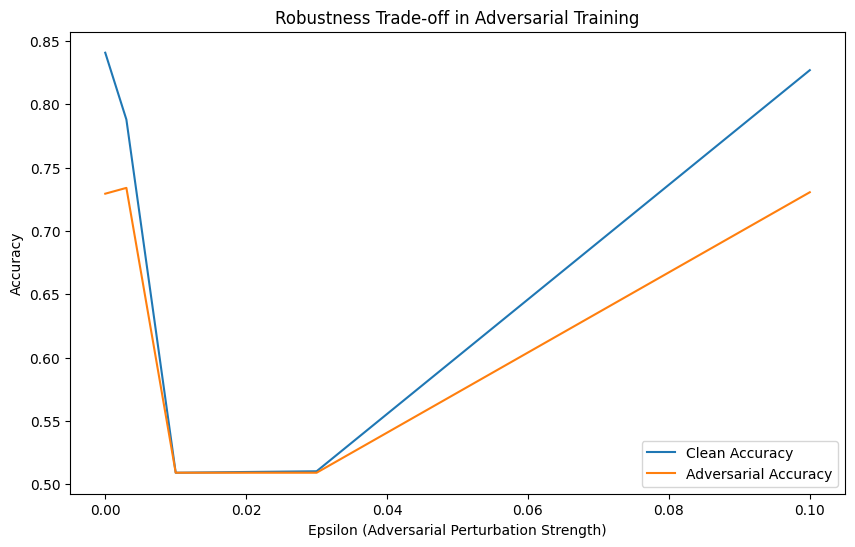

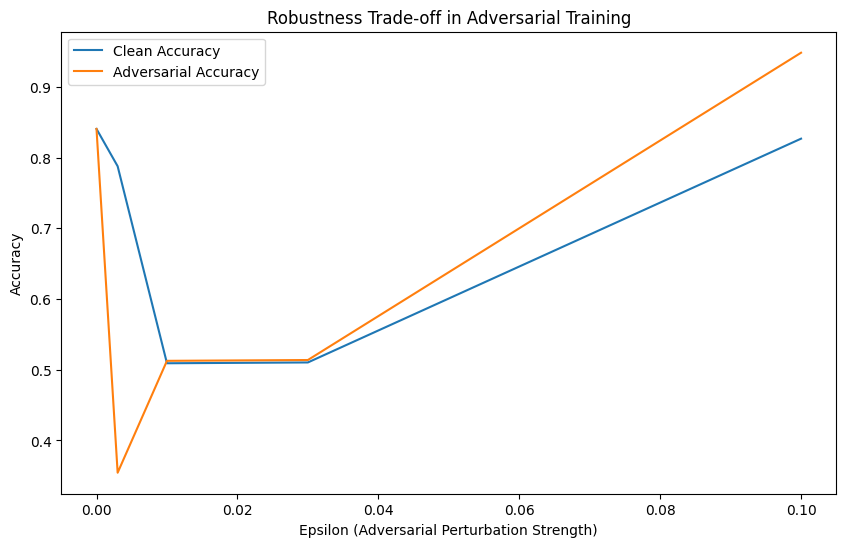

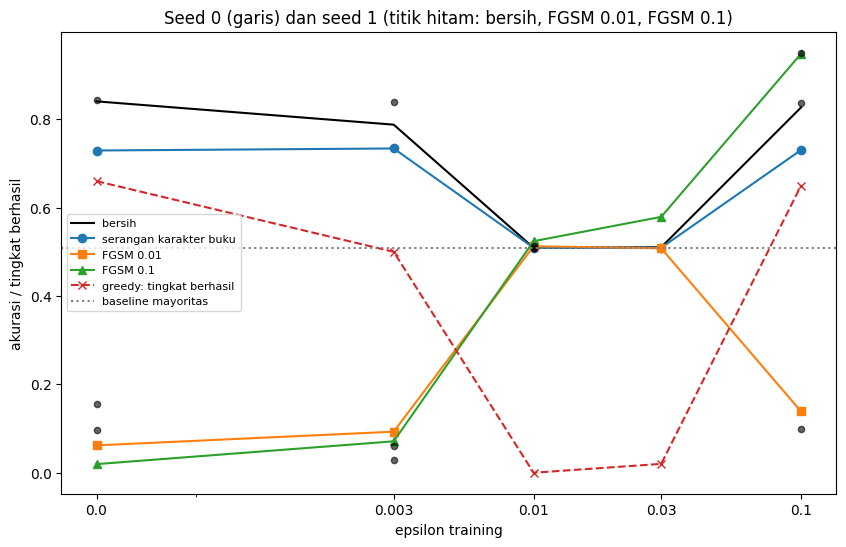

In [26]:
s0 = [s for s in sweep if s["seed"] == 0]
eps_values = [s["eps"] for s in s0]
plot_robustness_tradeoff([s["clean"] for s in s0], [s["char"] for s in s0], eps_values)        # gambar 1: serangan karakter buku
fgsm_at_train = [s["clean"] if s["eps"] == 0 else s[f"fgsm{s['eps']}"] for s in s0]             # epsilon 0: gangguan nol = input bersih
plot_robustness_tradeoff([s["clean"] for s in s0], fgsm_at_train, eps_values)                   # gambar 2: FGSM pada epsilon latih

fig, ax = plt.subplots(figsize=(10, 6))                                                         # gambar 3: semua ukuran sekaligus
for key, label, style in [("clean", "bersih", "k-"), ("char", "serangan karakter buku", "C0-o"), ("fgsm0.01", "FGSM 0.01", "C1-s"),
                          ("fgsm0.1", "FGSM 0.1", "C2-^"), ("greedy", "greedy: tingkat berhasil", "C3--x")]:
    ax.plot(eps_values, [s[key] for s in s0], style, label=label)
for s in sweep:
    if s["seed"] == 1:
        ax.plot([s["eps"]] * 3, [s["clean"], s["fgsm0.01"], s["fgsm0.1"]], "k.", ms=9, alpha=0.6)
ax.set_xscale("symlog", linthresh=0.003)
ax.set_xticks(eps_values)
ax.set_xticklabels([str(e) for e in eps_values])
ax.axhline(majority, color="gray", ls=":", label="baseline mayoritas")
ax.set_xlabel("epsilon training")
ax.set_ylabel("akurasi / tingkat berhasil")
ax.set_title("Seed 0 (garis) dan seed 1 (titik hitam: bersih, FGSM 0.01, FGSM 0.1)")
ax.legend(fontsize=8)
plt.show()

Tiga gambar tadi menggambar data yang sama dengan cara berbeda:

1. **Fungsi plot buku dengan serangan karakter** sebagai *adversarial accuracy*. Di run sebelumnya, kedua garis jatuh bersama ke 0,509 di epsilon 0,01 dan 0,03: celah antara bersih dan teradversarial menutup tepat di titik model tidak berguna.
2. **Fungsi yang sama dengan FGSM di epsilon latih.** Garis adversarial naik dan melampaui akurasi bersih di epsilon 0,1. Dibaca sekilas, adversarial training tampak sangat berhasil; padahal itu label leaking.
3. **Semua ukuran sekaligus**, dengan sumbu x log-simetris (agar 0, 0,003, dan 0,01 tidak berdempet), garis baseline mayoritas, dan titik hitam untuk seed kedua.

Fungsi plot buku menggambar apa pun yang diberikan kepadanya. Plot trade-off yang jujur butuh serangan yang tidak dipakai saat melatih, baseline mayoritas, proporsi tebakan per kelas, dan lebih dari satu seed. Tanpa itu, model konstan dan label leaking sama-sama tampak seperti ketahanan.

## Implikasi dunia nyata: kerangka deployment

Buku menutup bab dengan lima implikasi — risiko keamanan, misinformasi, kepercayaan pengguna, tanggung jawab hukum dan etis, serta kinerja di lingkungan nyata — dan satu kerangka kelas. Idenya sederhana: tolak input bila `attack_detector` menandainya; selain itu jalankan model dan olah keluarannya.

> **Listing buku: `RobustLLMDeployment`**
>
> ```python
> def process_input(self, text):
>     if self.attack_detector(text):
>         return "Potential adversarial input detected. Please try again."
>     inputs = self.tokenizer(...)
>     with torch.no_grad():
>         outputs = self.model(inputs)
>     return self.post_process_output(outputs)
> def post_process_output(self, outputs):
>     pass
> def log_interaction(self, input_text, output_text):
>     pass
> ```
>
> Di run sebelumnya, `self.model(inputs)` berhenti dengan `TypeError` yang sama seperti di `evaluate_robustness`. Setelah diganti `model(**inputs)`, kelas ini berjalan tetapi mengembalikan `None` untuk setiap kalimat, karena `post_process_output` hanya berisi `pass`. `log_interaction` juga tidak pernah dipanggil oleh `process_input`, jadi mengisinya saja tidak akan mencatat apa pun. Buku tidak menyediakan `attack_detector`.

Versi lengkap di bawah, `RobustSentimentDeployment`, memperbaiki ketiganya: input dipindah ke GPU dan dijalankan dengan `model(**inputs)`, keluarannya berupa label dan skor, dan setiap interaksi dicatat, termasuk yang ditolak. Untuk sementara detektornya tidak pernah menandai apa pun; detektor sungguhan dibangun sesudah ini.

In [27]:
class RobustSentimentDeployment:
    """Kerangka RobustLLMDeployment buku yang dilengkapi: model(**inputs) di device model, label + skor, log setiap interaksi."""

    def __init__(self, model, tokenizer, attack_detector):
        self.model = model
        self.tokenizer = tokenizer
        self.attack_detector = attack_detector
        self.log = []

    def process_input(self, text):
        if self.attack_detector(text):
            output = "Potential adversarial input detected. Please try again."
        else:
            inputs = self.tokenizer(text, return_tensors='pt', padding=True, truncation=True).to(DEVICE)
            with torch.no_grad():
                output = self.post_process_output(self.model(**inputs))
        self.log_interaction(text, output)
        return output

    def post_process_output(self, outputs):
        p = torch.softmax(outputs.logits, dim=-1)[0].cpu()
        k = int(p.argmax())
        return {"label": self.model.config.id2label[k], "score": round(float(p[k]), 4)}

    def log_interaction(self, input_text, output_text):
        self.log.append({"input": input_text, "output": output_text, "flagged": isinstance(output_text, str)})


dep = RobustSentimentDeployment(clf, tok, attack_detector=lambda text: False)   # sementara: detektor yang tak pernah menandai
for t in X_val[:3]:
    print(dep.process_input(t), "<-", t)
print("entri log:", len(dep.log))

{'label': 'POSITIVE', 'score': 0.9999} <- it 's a charming and often affecting journey .
{'label': 'NEGATIVE', 'score': 0.999} <- unflinchingly bleak and desperate
{'label': 'POSITIVE', 'score': 0.9996} <- allows us to hope that nolan is poised to embark a major career as a commercial yet inventive filmmaker .
entri log: 3


Setiap kalimat kini keluar dengan label dan skor, dan log berisi satu entri per kalimat. Kerangkanya sudah lengkap; yang masih kosong tinggal detektornya.

### Detektor untuk `attack_detector`

Dua detektor sederhana yang tidak perlu dilatih dengan contoh serangan:

- **fragmentasi wordpiece**: proporsi kata yang dipecah tokenizer DistilBERT menjadi lebih dari satu potongan. Kata yang rusak salah ketik biasanya tidak ada di kosakata. Ini murni pembukuan tokenizer, jadi berjalan di CPU.
- **perplexity GPT-2**: seberapa "terkejut" GPT-2 124M membaca teks itu, diukur sebagai rata-rata −log peluang setiap token (secara teknis *log-perplexity*, jadi angkanya kecil, bukan ratusan), dihitung di GPU. Teks yang rusak atau janggal mendapat peluang kecil, jadi skornya lebih tinggi.

Ambang setiap detektor diambil dari teks bersih: persentil ke-95 skornya pada separuh kalimat validation yang tidak dipakai di eksperimen greedy. Artinya, kira-kira 5% teks bersih akan ikut ditandai; inilah **positif palsu**. Separuh lainnya dipakai untuk memeriksa angka 5% itu.

In [28]:
rest = np.setdiff1d(np.arange(len(X_val)), idx1)                   # kalimat di luar sampel greedy
perm = np.random.default_rng(0).permutation(rest)
clean_cal = [X_val[i] for i in perm[:len(perm) // 2]]               # untuk menentukan ambang
clean_test = [(X_val[i], Y_val[i]) for i in perm[len(perm) // 2:]]  # untuk mengukur positif palsu: (teks, label emas)


def frag_score(texts):
    """(CPU) Proporsi kata alfabetis yang dipecah tokenizer menjadi lebih dari satu wordpiece."""
    out = []
    for t in texts:
        words = [w for w in t.lower().split() if w.isalpha()]
        out.append(np.mean([len(tok.tokenize(w)) > 1 for w in words]) if words else 0.0)
    return np.array(out)


LM = "openai-community/gpt2"
lm_tok = transformers.AutoTokenizer.from_pretrained(LM)
lm_tok.pad_token = lm_tok.eos_token                                 # GPT-2 tidak punya token pad
lm = transformers.AutoModelForCausalLM.from_pretrained(LM).to(DEVICE).eval()
print(device_report(lm, "GPT-2 124M"))


@torch.no_grad()
def ppl_score(texts, bs=32):
    """Rata-rata negative log-likelihood per token di bawah GPT-2 (log perplexity), dengan <|endoftext|> di depan."""
    out = []
    for i in range(0, len(texts), bs):
        enc = lm_tok([lm_tok.bos_token + t for t in texts[i:i + bs]], return_tensors="pt", padding=True).to(DEVICE)
        logits = lm(**enc).logits[:, :-1]
        nll = F.cross_entropy(logits.transpose(1, 2), enc["input_ids"][:, 1:], reduction="none")
        mask = enc["attention_mask"][:, 1:].float()
        out.extend(((nll * mask).sum(1) / mask.sum(1)).cpu().tolist())
    return np.array(out)


DET = {"fragmentasi": frag_score, "perplexity GPT-2": ppl_score}
thr = {k: np.quantile(f(clean_cal), 0.95) for k, f in DET.items()}
print(f"ambang (persentil 95 dari {len(clean_cal)} kalimat bersih): " + " | ".join(f"{k} {v:.3f}" for k, v in thr.items()))

GPT-2 124M: 124M parameter, semuanya di cuda
ambang (persentil 95 dari 286 kalimat bersih): fragmentasi 0.267 | perplexity GPT-2 6.638


Detektor diuji pada contoh serangan yang **berhasil** membalik prediksi, dari semua serangan sebelumnya. Ditambah satu serangan **adaptif**: greedy salah ketik yang hanya memakai salah ketik yang kebetulan berupa kata lain di kosakata (misalnya *seems* menjadi *seeks*). Itulah yang akan dilakukan penyerang yang tahu cara kerja detektor fragmentasi.

In [29]:
random.seed(0)
adv_c = [character_level_attack(s) for s in xs1]
flip_c = predict_proba(adv_c).argmax(1) != ys1
random.seed(0)
adv_w = [word_level_attack(s) for s in xs1]
flip_w = predict_proba(adv_w).argmax(1) != ys1
adv_t = [s + " " + T_found for s in pos_ok]
flip_t = predict_proba(adv_t).argmax(1) != 1


def in_vocab_cands(w, tag):
    """Serangan adaptif: hanya salah ketik yang tetap satu wordpiece utuh (kata lain di kosakata)."""
    return [c for c in char_cands(w, k=1000) if len(tok.tokenize(c)) == 1][:12]


res_adapt = [greedy_attack(s, y, in_vocab_cands) for s, y in zip(xs1[:n_ctrl], ys1[:n_ctrl])]
print(f"greedy adaptif, {n_ctrl} kalimat: berhasil {np.mean([r[1] for r in res_adapt]):.2f} "
      f"(greedy salah ketik biasa pada kalimat yang sama: {np.mean([r[1] for r in greedy_res['salah ketik'][:n_ctrl]]):.2f})")

SETS = {   # hanya contoh yang BERHASIL membalik prediksi; (teks, label emas)
    "karakter buku": [(a, y) for a, f, y in zip(adv_c, flip_c, ys1) if f],
    "sinonim buku": [(a, y) for a, f, y in zip(adv_w, flip_w, ys1) if f],
    "greedy salah ketik": [(r[0], y) for r, y in zip(greedy_res["salah ketik"], ys1) if r[1]],
    "greedy sinonim": [(r[0], y) for r, y in zip(greedy_res["sinonim"], ys1) if r[1]],
    "pemicu hasil pencarian": [(a, 1) for a, f in zip(adv_t, flip_t) if f],
    "greedy adaptif (kata utuh)": [(r[0], y) for r, y in zip(res_adapt, ys1[:n_ctrl]) if r[1]],
}
print(f"\n{'himpunan':<30} {'n':>4} {'fragmentasi':>12} {'perplexity':>11} {'salah satu':>11}   <- proporsi yang ditandai")
for name, pairs in [("bersih uji (= positif palsu)", clean_test)] + list(SETS.items()):
    texts = [t for t, _ in pairs]
    if not texts:
        print(f"{name:<30} {0:>4}   (tidak ada contoh)")
        continue
    flags = {k: DET[k](texts) > thr[k] for k in DET}
    either = flags["fragmentasi"] | flags["perplexity GPT-2"]
    print(f"{name:<30} {len(texts):>4} {flags['fragmentasi'].mean():>12.3f} {flags['perplexity GPT-2'].mean():>11.3f} {either.mean():>11.3f}")

greedy adaptif, 100 kalimat: berhasil 0.23 (greedy salah ketik biasa pada kalimat yang sama: 0.60)

himpunan                          n  fragmentasi  perplexity  salah satu   <- proporsi yang ditandai
bersih uji (= positif palsu)    286        0.045       0.059       0.105
karakter buku                    72        0.903       0.972       1.000
sinonim buku                     13        0.077       0.231       0.231
greedy salah ketik              203        0.158       0.256       0.320
greedy sinonim                  163        0.080       0.190       0.252
pemicu hasil pencarian          388        0.015       0.198       0.211
greedy adaptif (kata utuh)       23        0.000       0.391       0.391


Di run sebelumnya, positif palsu masing-masing detektor 0,045 dan 0,059, dekat target 5%. Detektor gabungan (tandai bila salah satu menandai) mencapai 0,105: menggabungkan dua detektor menggandakan positif palsu.

- **Serangan karakter buku hampir selalu tertangkap** (gabungan 1,000), karena ia merusak banyak kata sekaligus.
- **Serangan yang hemat edit sebagian besar lolos.** Contoh greedy salah ketik hanya tertangkap 0,320, greedy sinonim 0,252, dan pemicu *wears off total* 0,211. Frasa yang fasih tidak tampak seperti serangan.
- **Penyerang adaptif menghindari detektor yang ia kenal.** Greedy kata-utuh lebih jarang berhasil (0,23 lawan 0,60 pada 100 kalimat yang sama), tetapi contoh yang berhasil sama sekali tidak tertangkap fragmentasi (0,000); perplexity menandai 0,391.

Kedua detektor menilai **bentuk** teks, bukan niatnya. Yang tertangkap dengan andal hanya serangan yang merusak banyak kata.

Terakhir, satu contoh dari setiap himpunan dikirim ke `RobustSentimentDeployment` dengan detektor gabungan.

In [30]:
def attack_detector(text):
    """Detektor gabungan: tandai bila fragmentasi ATAU perplexity melewati ambang teks bersih."""
    return bool(frag_score([text])[0] > thr["fragmentasi"] or ppl_score([text])[0] > thr["perplexity GPT-2"])


dep_final = RobustSentimentDeployment(clf, tok, attack_detector)
examples = [("bersih", clean_test[0])] + [(k, v[0]) for k, v in SETS.items() if v]
for name, (text, gold) in examples:
    print(f"{name:<28} label emas {clf.config.id2label[int(gold)]:<8} -> {dep_final.process_input(text)}")
    print(f"{'':<28} {text}")
flagged = sum(e["flagged"] for e in dep_final.log)
print(f"\nlog: {len(dep_final.log)} entri, {flagged} ditandai sebagai serangan")

bersih                       label emas POSITIVE -> {'label': 'POSITIVE', 'score': 0.9998}
                             like leon , it 's frustrating and still oddly likable .
karakter buku                label emas POSITIVE -> Potential adversarial input detected. Please try again.
                             something akin to a japanese alice Uhrough thK loouing glass , Zxcept thWt ft seems to take iNself far mYre seriOuslh .
sinonim buku                 label emas POSITIVE -> {'label': 'NEGATIVE', 'score': 0.9959}
                             Ferdinand_Joseph_La_Menthe_Morton uses her face and her body language to bring us morvern 's individual , yet though the character_reference is almost completely deadpan .
greedy salah ketik           label emas POSITIVE -> {'label': 'NEGATIVE', 'score': 0.9902}
                             something akin to a japanese alice through the looking glass , except that it seems to take itself far more seriouely .
greedy sinonim               label 

Di run sebelumnya, kalimat bersih lolos dengan label benar, dua serangan ditolak (serangan karakter buku dan pemicu), dan empat lolos dengan label salah, termasuk *seems* → *seeks* dari serangan adaptif. Kerangka buku kini lengkap — penolakan, label, skor, dan log audit — tetapi detektornya meloloskan sebagian besar serangan yang hemat edit.

## Ringkasan

Angka dan pola di ringkasan ini berasal dari run sebelumnya; output GPU di atas bisa sedikit berbeda.

- **Membuat gangguan.** Serangan karakter dan sinonim di buku tidak pernah bertanya ke model, jadi keduanya mengukur ketahanan terhadap noise. Serangan greedy yang bertanya ke model membalik jauh lebih banyak kalimat dengan edit lebih sedikit (0,677 dengan 2,1 kata, lawan 0,245 dengan 6,4 kata), dan sebagian besar kekuatannya datang dari akses bertanya itu sendiri.
- **Pemicu universal.** Di model sentimen ini, contoh pemicu di buku berperilaku seperti frasa acak. Pencarian gradien menemukan pemicu yang benar-benar universal, tetapi pemicu itu membawa sentimen negatif yang bisa dibaca model.
- **Adversarial training.** Listing buku butuh beberapa perbaikan sebelum jalan. Epsilon 0,1 di embedding bukan gangguan kecil dan tidak berwujud teks. Di sweep, adversarial training kira-kira dua kali lebih mahal, bisa meruntuhkan model menjadi tebakan konstan, dan di epsilon 0,1 menghasilkan label leaking tanpa ketahanan terhadap serangan teks.
- **Evaluasi.** Pasangan akurasi bersih dan teradversarial perlu dibaca bersama tingkat keberhasilan serangan, baseline mayoritas, proporsi tebakan per kelas, dan beberapa seed. Undian serangan saja bisa menggeser akurasi teradversarial sekitar 4 poin.
- **Deployment.** Kerangka buku perlu dilengkapi agar mengembalikan hasil dan mencatat interaksi. Detektor bentuk teks menangkap serangan yang kasar, tetapi meloloskan serangan yang hemat edit dan serangan adaptif.

**Berikutnya:** Chapter 19 membahas Reinforcement Learning from Human Feedback (RLHF). Di sana, keluaran model bahasa dinilai oleh *reward model*: model yang memberi skor pada teks, mirip cara DistilBERT SST-2 memberi skor sentimen di bab ini. Bab ini sudah memperlihatkan betapa mudahnya skor semacam itu dibalik oleh input yang dicari dengan sengaja.